# Final project P10 · The Price of Dinner
**Data Visualization · UEH · Final group project** · team notebook

| | |
|---|---|
| **Team** | Team 10 · team name *(not chosen yet)* |
| **Members** | Nguyễn Hoàng Minh (leader), Phạm Quang Minh, Phạm Tuấn Anh, Trần Nhã Đoan, Nguyễn Minh Nguyệt, Trần Nguyễn Thanh Thảo |
| **Client** | Consumer Lab, a consumer rights association |
| **Big question** | Where should a student on a tight budget buy food in Ho Chi Minh City: at the wet market, at the supermarket or through a delivery app? |
| **Status** | Updated on 26 October 2026. M0 to M3 have a full draft; M4 to M10 wait for weeks 3 to 8 of the price data and for the student survey |
| **How to run** | Run `python data/raw/download_raw.py` once from the repository root (or set `REFRESH = True` in Setup), then *Restart and run all* |

This notebook holds the whole project, from Module M0 to Module M10, in the order of the brief. Every number in a chart title is printed by the code next to it, and every figure is also saved in `report/figures/`. Before anyone edits this notebook, they read `AGENTS.md` (the writing and chart rules of the team) and the latest entries of `CHANGELOG.md`, and they add a changelog entry when they finish. The project website, in Vietnamese, is https://p10-price-of-dinner.vercel.app.

## Summary for Consumer Lab (write this last)
**Big Idea v0:** A student who **[persona]** can save **[X to Y]%** of a weekly food basket by buying **[item group]** at the **[channel]**, but this saving **[stays / shrinks]** once **[travel time / delivery fees / food waste]** is counted.

My group fills in the numbers after week 8. The first two weeks point in one direction: for the same item, district and week, the supermarket costs about 1.1 times the wet market price, and the delivery app about 1.4 times. These are 45 comparisons from two of eight weeks, so they are a first signal and not a result.

### Module map

| Module | Topic | Lead | Checkpoint | Status on 26 October 2026 |
|---|---|---|---|---|
| M0 | Project setup: brief, team, repository, raw data | Nguyễn Hoàng Minh | | Done |
| M1 | Frame the problem: interview, question tree, Big Idea v0, team contract | *(fill in)* | CP0, CP1 | Draft done; a second short call is needed (Section M1.1) |
| M2 | Acquire, abstract and clean the data | *(fill in)* | CP1 | Done for weeks 1 and 2; reruns each week |
| M3 | House style, colour check, makeover, honest and misleading pair | *(fill in)* | | Draft done; the 150 word text needs a final read |
| M4 | Core charts that answer the four questions | *(fill in)* | | Two preliminary charts; needs more weeks |
| M5 | Dashboard and a second tool | *(fill in)* | | Not started |
| M6 | Hidden structure: PCA and clustering | *(fill in)* | | Not started; needs weeks 3 to 8 |
| M7 | Many dimensions: heatmap, treemap, parallel coordinates | *(fill in)* | CP2 | Not started |
| M8 | Beyond the flat screen: 3D view and experiment | *(fill in)* | | Not started |
| M9 | Interaction, animation and story | *(fill in)* | CP3 | Not started |
| M10 | Evaluation and improvement | *(fill in)* | CP4 | Not started |

## Setup
The first cell writes `house_style.py` next to this notebook, so the style lives in one place and every chart uses it. My group explains each rule of the style in Module M3. The second cell sets the folders and loads the libraries.

In [1]:
%%writefile house_style.py
"""House style for P10 The Price of Dinner.

Every notebook starts with:

    from house_style import *
    apply_style()

The style follows one rule: a chart shows one finding. Context is grey, the element that
carries the finding gets the highlight colour, the title states the finding, and the
subtitle gives the units. Labels sit next to the data instead of in a legend.
"""

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb

# ---------------------------------------------------------------- colours

INK = "#1A1A1A"        # text, axes, the highlight in black and white charts
GREY = "#8C8C8C"       # context data
LIGHT = "#D9D9D9"      # grid lines, empty bars, faint context
PAPER = "#FFFFFF"

# One colour per shopping channel, always in this order and always with these colours.
# The three colours differ in lightness (L* 50, 25, 75), so they also work in greyscale,
# and they stay apart under protan, deutan and tritan simulation (see cvd_report below).
CHANNEL_ORDER = ["Chợ", "Siêu thị", "App"]
CHANNEL = {"Chợ": "#B85C38", "Siêu thị": "#1F3D55", "App": "#9BBDD6"}
CHANNEL_EN = {"Chợ": "Wet market", "Siêu thị": "Supermarket", "App": "Delivery app"}

# Districts never get their own colour: they get a line style or a marker.
DISTRICT_ORDER = ["Quận 10", "Quận 3"]
DISTRICT_LINE = {"Quận 10": "-", "Quận 3": "--"}
DISTRICT_MARKER = {"Quận 10": "o", "Quận 3": "s"}

HIGHLIGHT = CHANNEL["Chợ"]  # single highlight colour for one-finding charts

# Sequential map for amounts (light to dark blue) and diverging map for changes
# (blue below the centre, terracotta above). Centre the diverging map with
# TwoSlopeNorm at 100 for an index or at 0 for a percentage change.
SEQ = LinearSegmentedColormap.from_list("p10_seq", ["#F2F5F8", "#1F3D55"])
DIV = LinearSegmentedColormap.from_list("p10_div", ["#1F3D55", "#F7F7F7", "#B85C38"])


def div_norm(center=100.0, spread=20.0):
    """A diverging norm centred on `center` (100 for an index, 0 for a % change)."""
    return TwoSlopeNorm(vcenter=center, vmin=center - spread, vmax=center + spread)


# ---------------------------------------------------------------- numbers

def fmt_vnd(x, short=True):
    """45000 -> '45k' (short) or '45,000 VND'."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ""
    if short:
        return f"{x / 1000:,.0f}k" if abs(x) >= 1000 else f"{x:,.0f}"
    return f"{x:,.0f} VND"


def fmt_pct(x, digits=0, sign=False):
    """0.123 -> '12%'; with sign=True -> '+12%'."""
    return f"{x:+.{digits}%}" if sign else f"{x:.{digits}%}"


# ---------------------------------------------------------------- matplotlib defaults

def apply_style():
    """Set the house defaults for every figure in the notebook."""
    mpl.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Georgia", "DejaVu Serif", "Times New Roman", "serif"],
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
        "axes.titlesize": 12.5,
        "axes.titleweight": "bold",
        "axes.titlepad": 22,
        "axes.labelsize": 9.5,
        "axes.grid": False,
        "xtick.color": INK,
        "ytick.color": INK,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "figure.dpi": 110,
        "figure.facecolor": PAPER,
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
        "savefig.facecolor": PAPER,
    })


def title(ax, text, subtitle=None):
    """Action title in bold and an italic subtitle with the units, both left aligned."""
    ax.set_title(text, loc="left")
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5,
                style="italic", color=INK, va="bottom", ha="left")


def figure_title(fig, text, subtitle=None, y=1.0):
    """Headline for a multi-panel figure."""
    fig.text(0.01, y, text, fontsize=17, fontweight="bold", ha="left", va="bottom")
    if subtitle:
        fig.text(0.01, y - 0.012, subtitle, fontsize=10.5, style="italic", ha="left", va="top")


def note(fig, text, y=-0.02):
    """Source and limitation line at the bottom of a figure."""
    fig.text(0.01, y, text, fontsize=8.5, color=INK, ha="left", va="top", style="italic")


def _trim(path, pad=40):
    """Cut the empty white border of a saved PNG (3D axes leave a lot of it)."""
    from PIL import Image, ImageChops
    im = Image.open(path).convert("RGB")
    box = ImageChops.difference(im, Image.new("RGB", im.size, (255, 255, 255))).getbbox()
    if box:
        im.crop((max(box[0] - pad, 0), max(box[1] - pad, 0),
                 min(box[2] + pad, im.width), min(box[3] + pad, im.height))).save(path)


def save(fig, path, pdf=False):
    """Save a figure as PNG with the house settings; pdf=True also writes a PDF (needed for the M5 dashboard)."""
    fig.savefig(path)
    if str(path).endswith(".png"):
        _trim(path)
        if pdf:
            fig.savefig(str(path)[:-4] + ".pdf")


# ---------------------------------------------------------------- 3D style
# The team draws its charts as 3D columns. Three rules keep them honest: columns start at zero,
# every column that carries the finding has its value printed, and the view stays low (elev about 20)
# so that the tops of the columns do not drift away from their values.

def tint(color, f):
    """Mix a colour with white (f > 0) or with black (f < 0)."""
    r = np.array(to_rgb(color))
    return tuple(r + (1 - r) * f) if f > 0 else tuple(r * (1 + f))


def faces3d(color):
    """Face colours for one ax.bar3d column: light top, base colour in front, darker sides."""
    # bar3d face order: bottom, top, front (-y), back (+y), left (-x), right (+x)
    return [tint(color, -0.2), tint(color, 0.35), color, color, tint(color, -0.25), tint(color, -0.25)]


def bars3d(ax, x, y, heights, colors, width=0.6, depth=0.6, base=0.0, edge="white"):
    """Draw 3D columns centred on (x, y); `colors` is one colour per column."""
    x, y, h = (np.atleast_1d(np.asarray(v, dtype=float)) for v in (x, y, heights))
    face = sum((faces3d(c) for c in colors), [])
    ax.bar3d(x - width / 2, y - depth / 2, np.full_like(h, base), width, depth, h - base,
             color=face, shade=False, edgecolor=edge, linewidth=0.4)


def style3d(ax, elev=20, azim=-60, aspect=(3, 1.4, 1.6), zoom=1.0, grid=False, zaxis=True, yaxis=True):
    """House look for a 3D axes: no panes, no grid, thin grey axis lines, a low view.

    zaxis=False hides the value axis; use it when every column carries its printed value.
    """
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect(aspect, zoom=zoom)
    ax.grid(grid)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.set_pane_color((1, 1, 1, 0))
        a.pane.set_edgecolor((1, 1, 1, 0))
        a._axinfo["grid"]["color"] = (0, 0, 0, 0.08)
        a.line.set_color(GREY)
        a.line.set_linewidth(0.6)
    if not zaxis:
        ax.set_zticks([])
        ax.zaxis.line.set_color((1, 1, 1, 0))
    if not yaxis:
        ax.set_yticks([])
        ax.yaxis.line.set_color((1, 1, 1, 0))
    ax.tick_params(axis="both", pad=0, colors=INK, labelsize=8.5, length=0)


def label3d(ax, x, y, z, text, dx=0, dy=12, **kw):
    """Write `text` at the 3D point (x, y, z), drawn in 2D on top so that no column hides it."""
    from mpl_toolkits.mplot3d import proj3d
    sx, sy, _ = proj3d.proj_transform(x, y, z, ax.get_proj())
    kw.setdefault("fontsize", 9)
    kw.setdefault("ha", "center")
    kw.setdefault("va", "bottom")
    return ax.annotate(text, xy=(sx, sy), xytext=(dx, dy), textcoords="offset points", zorder=20, **kw)


def title3d(ax, text, subtitle=None):
    """Action title and subtitle for a 3D axes (set_title sits too high on 3D axes)."""
    ax.text2D(0, 1.02, text, transform=ax.transAxes, fontsize=12.5, fontweight="bold", va="bottom")
    if subtitle:
        ax.text2D(0, 0.985, subtitle, transform=ax.transAxes, fontsize=9.5, style="italic", va="top")


# ---------------------------------------------------------------- colour vision check

_CVD = {   # Machado, Oliveira and Fernandes (2009), severity 1.0, applied in linear RGB
    "protan": np.array([[0.152286, 1.052583, -0.204868],
                        [0.114503, 0.786281, 0.099216],
                        [-0.003882, -0.048116, 1.051998]]),
    "deutan": np.array([[0.367322, 0.860646, -0.227968],
                        [0.280085, 0.672501, 0.047413],
                        [-0.011820, 0.042940, 0.968881]]),
    "tritan": np.array([[1.255528, -0.076749, -0.178779],
                        [-0.078411, 0.930809, 0.147602],
                        [0.004733, 0.691367, 0.303900]]),
}


def _lin(c):
    c = np.asarray(c, dtype=float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _unlin(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, c * 12.92, 1.055 * c ** (1 / 2.4) - 0.055)


def _lab(rgb):
    m = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    t = (m @ _lin(rgb)) / np.array([0.95047, 1.0, 1.08883])
    f = np.where(t > 216 / 24389, np.cbrt(t), (24389 / 27 * t + 16) / 116)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])


def simulate(color, kind):
    """RGB tuple of `color` as seen with protan, deutan or tritan vision, or in greyscale."""
    rgb = np.array(to_rgb(color))
    if kind == "normal":
        return tuple(rgb)
    if kind == "greyscale":
        y = _unlin(np.array([0.2126, 0.7152, 0.0722]) @ _lin(rgb))
        return (float(y),) * 3
    return tuple(_unlin(_CVD[kind] @ _lin(rgb)))


def cvd_report(colors=None):
    """Smallest colour difference (CIE76 delta E) between any two colours, per vision type.

    A delta E above about 20 is easy to tell apart on screen.
    """
    if colors is None:
        colors = CHANNEL
    if isinstance(colors, dict):
        colors = list(colors.values())
    out = {}
    for kind in ["normal", "protan", "deutan", "tritan", "greyscale"]:
        labs = [_lab(np.array(simulate(c, kind))) for c in colors]
        out[kind] = min(np.linalg.norm(a - b) for i, a in enumerate(labs) for b in labs[i + 1:])
    return out


Overwriting house_style.py


In [2]:
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, to_rgba
from IPython.display import display

import importlib, house_style
importlib.reload(house_style)
from house_style import *
apply_style()
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN, FIG = ROOT / "data" / "raw", ROOT / "data" / "clean", ROOT / "report" / "figures"
for folder in (CLEAN, FIG):
    folder.mkdir(parents=True, exist_ok=True)

REFRESH = False     # True downloads the team sheet and the public files again (needs internet)
WEEK1_START = pd.Timestamp("2026-10-12")      # Monday of collection week 1
print("Repository root:", ROOT)

Repository root: /Users/nguyenhoangminh/DataViz_Final_P10


In [3]:
# The download functions of data/raw/download_raw.py, run only when REFRESH is True
"""Download every raw file that notebooks/01_data.ipynb reads.

Run from the repository root:  python data/raw/download_raw.py

The script never edits a file after download. Each run saves a dated copy of the team's
price sheet, so earlier snapshots stay available for checking.

Sources
1. Team price sheet (primary data): Google Sheet "P10 · The Price of Dinner · Bảng thu giá",
   exported as xlsx. The sheet is shared by link, so no login is needed.
2. NSO Viet Nam (formerly GSO): monthly CPI press release tables, one xlsx per month,
   found through the CPI listing page https://www.nso.gov.vn/en/cpi/.
3. FAOSTAT: Consumer Price Indices, bulk download (all countries, normalized).
4. World Bank: Commodity Price Data ("Pink Sheet"), monthly prices.
"""

import datetime as dt
import re
import urllib.request
from pathlib import Path

RAW = ROOT / "data" / "raw"
PRIMARY = RAW / "primary"
PUBLIC = RAW / "public"
SHEET_ID = "1f6CMh-ICjBKUe3QGSaUeeAVF4M5Ol_N5suMf_-ZIDo0"
HEADERS = {"User-Agent": "Mozilla/5.0 (P10 student project, UEH)"}


def fetch(url, timeout=90):
    req = urllib.request.Request(url, headers=HEADERS)
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()


def save_raw(content, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    print(f"saved {path.relative_to(RAW.parent.parent)} ({len(content) / 1024:,.0f} KB)")


def team_sheet():
    today = dt.date.today().strftime("%Y%m%d")
    url = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=xlsx"
    save_raw(fetch(url), PRIMARY / f"price_sheet_{today}.xlsx")


def nso_cpi():
    pages = set()
    for suffix in ["", "page/2/", "page/3/"]:
        html = fetch(f"https://www.nso.gov.vn/en/cpi/{suffix}").decode("utf-8", "ignore")
        pages |= set(re.findall(r'https://www\.nso\.gov\.vn/en/data-and-statistics/20\d\d/\d\d/consumer-price-index[^"]*', html))
    for page in sorted(pages):
        html = fetch(page).decode("utf-8", "ignore")
        # The period is written either as "9/2026" or as "May 2026".
        period = re.search(r"Reference period:\s*(?:<[^>]+>\s*)*([A-Za-z]+|\d{1,2})[ /](\d{4})", html)
        links = re.findall(r'href="([^"]+\.xlsx)"', html)
        if not (period and links):
            print("skipped (no period or table):", page)
            continue
        m = period.group(1)
        month = int(m) if m.isdigit() else dt.datetime.strptime(m[:3], "%b").month
        year = int(period.group(2))
        save_raw(fetch(links[0]), PUBLIC / "nso_cpi" / f"nso_cpi_{year}_{month:02d}.xlsx")


def faostat_cpi():
    url = "https://bulks-faostat.fao.org/production/ConsumerPriceIndices_E_All_Data_(Normalized).zip"
    save_raw(fetch(url, timeout=180), PUBLIC / "faostat_cpi_normalized.zip")


def world_bank_pink_sheet():
    page = fetch("https://www.worldbank.org/en/research/commodity-markets").decode("utf-8", "ignore")
    url = re.findall(r'https?://[^"]*CMO-Historical-Data-Monthly[^"]*\.xlsx', page)[0]
    save_raw(fetch(url, timeout=180), PUBLIC / "worldbank_cmo_monthly.xlsx")



if REFRESH:
    for step in [team_sheet, nso_cpi, faostat_cpi, world_bank_pink_sheet]:
        try:
            step()
        except Exception as err:
            print(f"FAILED {step.__name__}: {err}")

SHEET = sorted((RAW / "primary").glob("price_sheet_*.xlsx"))[-1]      # newest snapshot of the team sheet
SHEET_DATE = pd.to_datetime(re.search(r"(\d{8})", SHEET.stem).group(1)).strftime("%d %B %Y").lstrip("0")
print("Price sheet snapshot:", SHEET.name)

Price sheet snapshot: price_sheet_20261026_2006.xlsx


---
# M0 · Project setup
### M0.1 The brief in one table

| Part | What the brief asks |
|---|---|
| Client and role | Consumer Lab; my group works as its research officers |
| Big question | Where should a student on a tight budget buy food, and how much can the channel choice save? |
| Primary data | At least 500 prices that my group collects: 12 items × 3 channels × 2 districts × 8 weeks = 576 planned |
| Survey | At least 60 students, for the three personas of the basket question |
| Public data | At least two public sources, mixed with our own data (my group uses NSO, FAOSTAT and the World Bank) |
| Collector rule | Each record carries the collector, the date and the time; each member is the collector of at least 20% of the records |
| Grading | Group project 40% of the course, final report 20% |
| What the client must be able to do | Repeat the Big Idea in one sentence, see the evidence in at most three explanatory charts, explore the details in an explorer, and trust the data |

### M0.2 Team and items

| Member | Branch | Items whose specification they wrote |
|---|---|---|
| Nguyễn Hoàng Minh (leader) | `hwinh` | SP01 Pork belly, SP02 Water spinach |
| Phạm Quang Minh | `quang-minh` | SP03 Mackerel, SP04 Tomato |
| Phạm Tuấn Anh | `tuan-anh` | SP05 Beef, SP06 Free range chicken |
| Trần Nhã Đoan | `nha-doan` | SP07 Watermelon, SP08 Onion |
| Nguyễn Minh Nguyệt | `minh-nguyet` | SP09 Đà Lạt potato, SP10 White tofu |
| Trần Nguyễn Thanh Thảo | `thao` | SP11 Chicken eggs, SP12 Red tilapia |

Each member wrote the specification of two items. The collection schedule rotates: every week the sheet gives each member two items, so every member visits different items over the eight weeks.

### M0.3 How my group works
Each member works on their own branch and opens a pull request into `dev`. The leader reviews and merges it, and only `dev` can go into `main`. The README explains the steps. Every member, and every AI agent that a member uses, follows `AGENTS.md`, so that the text and the charts look like the work of one team.

### M0.4 Raw data
The cell in Setup downloads four sources when `REFRESH = True`: the team price sheet (a dated xlsx snapshot), the NSO monthly CPI tables, the FAOSTAT consumer price indices and the World Bank Pink Sheet. My group never edits a raw file; every change happens in Module M2.

---
# M1 · Frame the problem
This module holds the interview, the question tree, Big Idea v0, the proposal for CP1 and the team contract. The text also lives in `report/M1_frame_the_problem.md`.

### M1.1 Stakeholder interview

#### M1.1.1 How my group ran the interview

| Item | Detail |
|---|---|
| Date and format | 22 October 2026, 21:09, Microsoft Teams, audio only |
| Respondent | A woman who shops for her family and lives in Tân Phú District. She did not give her name, and my group keeps her anonymous |
| Why this person | The lecturer asked each group to interview someone who buys food for a household. Her shopping covers all three channels in our study |
| Interviewers | Members of my group; Nguyễn Hoàng Minh organised the call and Phạm Quang Minh recorded it |
| Consent | At 04:04, the interviewer explained that the interview was for a course project and asked for permission. She agreed at 04:22. At 22:57, the interviewer promised that her answers would be used only for the course and that no personal details would be shared |
| Length | The whole recording lasts 24 minutes 16 seconds. The interview itself runs from 04:04 to 23:15, which is about 19 minutes |
| Questions | Eight open questions based on *The Mom Test*: each question asks about a recent, real event instead of an opinion about the future |
| Transcript | The audio was transcribed with Whisper (model `large-v3-turbo`). A member then listened again and corrected the wrong words. The full transcript stays in `evidence/`, which git does not publish |

**A gap that my group must close.** The brief asks for an interview of at least 20 minutes. Our formal interview is about one minute short. My group will make a second, short call with the same person, of about 10 minutes, for three reasons. First, the call brings the interview time above 20 minutes. Second, two parts of the recording are unclear: the shop that sold watermelon at 18,000 to 19,000 VND per kg (08:54), and the area she called "near 12" (11:39). Third, the brief says that the lecturer may contact the respondent, so my group needs her permission to share a phone number or an email with the lecturer.

#### M1.1.2 What my group learned

The table links each finding to one of our four smaller questions (Section M1.2). The times refer to the recording.

| Finding | Evidence from the interview | Question |
|---|---|---|
| She splits her basket by channel. She buys vegetables, tofu, onions, lemons and spices at the wet market, and pork, eggs and milk at the supermarket | 06:56. The market is cheaper, she can bargain, and she can buy a small amount. The supermarket keeps meat cold, so she trusts it more | Q1 |
| The price gap for the same item is a few thousand VND | Watermelon: 17,000 VND per kg at the supermarket, 18,000 to 20,000 VND per kg elsewhere (08:54). A 300 g bunch of water spinach: 9,000 VND at one supermarket and 12,000 VND at another (08:54) | Q1 |
| She sees little quality difference between two supermarkets, but the time of day matters | 10:08. The same 300 g bunch looks similar in both shops; freshness depends on morning or afternoon | Q1 |
| Prices differ between areas of the city | Tofu costs 5,000 to 6,000 VND per piece near her home and 3,500 to 4,000 VND near a friend's home in another district (11:03). Some vegetables differ by 3,000 to 4,000 VND | Q2 |
| She notices a price rise by comparing it with her last purchase | Water spinach went from 9,000 to about 12,000 VND per bunch a week before the interview (12:38). She guessed that weather or transport costs were the cause | Q3 |
| One small rise does not matter, but many small rises add up | 13:47. She switches to a cheaper vegetable with similar nutrition | Q3, Q4 |
| Splitting the basket saves money but costs time | 14:58. She saves from 5,000 VND to a few tens of thousands VND per trip, and a few tens of thousands VND per week. She often visits two places. On busy days she goes only to the supermarket | Q4 |
| A cheap price is not always a saving | 18:01. Evening discounts of 30% to 50% gave her vegetables that were wilted inside, and she threw a large part away. Now she checks more carefully or pays more at another shop | Q4 |
| Convenience can beat price | 21:16. Late at night, when the supermarket is closed, she orders fruit on GrabMart or buys it at a convenience store. A bunch of bananas costs about 20,000 VND at the supermarket, while one banana costs about 10,000 VND or more at a convenience store or on an app | Q1, Q4 |

#### M1.1.3 What the interview changes in our design

1. **The unit matters.** She talks about prices per bunch, per piece and per kg. My group therefore records the pack size of every price and converts it to a price per kg (Module M2).
2. **The time of day matters.** Evening discounts and freshness change during the day, so the price sheet records the time of every price.
3. **The cheapest price is not the full cost.** Travel time, the number of trips, the delivery fee and food waste all change what a student really pays. Our student survey will ask about these costs, and the basket cost in Q4 will show the price and the extra costs separately.
4. **The delivery app is a channel for urgent or late purchases.** My group will not judge the app by price alone. The final guide will say when the app is worth its higher price.

### M1.2 Question tree

**Big question:** Where should a student on a tight budget buy food in Ho Chi Minh City, and how much can the choice of channel save?

| Question | Tasks (action and target) | Main chart | Data | Module |
|---|---|---|---|---|
| **Q1.** How large is the price gap between channels for the same item, and does it stay the same over eight weeks? | Compare the price per kg across the three channels for each of the 12 items. Track the gap between channels week by week. Rank the items by the size of the gap | Dot plot per item; line chart of the weekly gap | Team price sheet | M4, M7 |
| **Q2.** Do prices differ between Quận 10 and Quận 3? | Compare the two districts for each item and channel. Find the items with the largest district gap | Dumbbell chart | Team price sheet | M4, M7 |
| **Q3.** How do the price changes that we observe compare with the official food CPI? | Build a price index from our data (week 1 = 100). Compare it with the NSO CPI groups "Foodstuff" and "Food and foodstuff" for Ho Chi Minh City. Place both against world prices of rice, oil and meat | Two panels on the same time axis (no dual axis) | Team price sheet, NSO, FAOSTAT, World Bank | M4 |
| **Q4.** How much does a real student basket cost, and how much can the channel choice save? | Estimate the weekly basket cost for three student personas. Add travel time, delivery fees and waste to the price. Rank the channels by real saving | Bar chart per persona with the price and the extra costs shown separately | Price sheet, student survey (at least 60 students) | M4, M7, M9 |

Each task needs at least one chart. The chart list in Module M4 will refer to these task names.

### M1.3 Big Idea v0

My group uses the template from the brief and leaves the numbers open until the eight weeks of data are complete.

> A student who **[persona]** can save **[X to Y]%** of a weekly food basket by buying **[item group]** at the **[channel]**, but this saving **[stays / shrinks]** once **[travel time / delivery fees / food waste]** is counted.

**Our working hypothesis.** The interview suggests that the wet market is cheaper for vegetables and that the supermarket wins on trust for meat. My group expects the delivery app to cost the most, but to be the only option for some late purchases. The first two weeks of our data point in the same direction: for the same item, district and week, the supermarket price is about 1.1 times the wet market price, and the app price is about 1.4 times. These numbers come from only 45 complete comparisons, so my group does not treat them as a result yet.

### M1.4 Proposal on one page (CP1)

#### M1.4.1 Question and plan

The question tree in Section M1.2 is our plan. Every smaller question has a task, a chart and a data source.

#### M1.4.2 Sources tested

My group downloaded every source and read one real row from each.

| Source | What it gives | One row that my group read |
|---|---|---|
| Team price sheet (primary) | Price of 12 items × 3 channels × 2 districts × 8 weeks | Week 1, SP01 pork belly, Grab Mart, Quận 10, 18 October 2026, 12:00: 192,000 VND per kg, promotion, delivery fee 41,000 VND |
| NSO Viet Nam, monthly CPI | CPI by group for Viet Nam and Ho Chi Minh City | September 2026, Ho Chi Minh City, "Foodstuff": 100.19 (previous month = 100) |
| FAOSTAT, consumer price indices | Viet Nam food CPI, 2015 = 100 | June 2026, Viet Nam, food: 140.87 |
| World Bank, Pink Sheet | World commodity prices in US dollars | September 2026, rice (Viet Nam 5% broken): 418.50 USD per tonne |

The data cards in `data/data_cards.md` describe each source in full. The old GSO address (gso.gov.vn) did not respond, so my group uses the new NSO address.

#### M1.4.3 Field data plan

| Part | Plan |
|---|---|
| Price collection | 576 planned prices from 12 October to 6 December 2026. Each member owns two items and checks them in all six channel and district cells every week. The app alternates between Grab Mart (odd weeks) and Shopee Mart (even weeks) |
| Item specification | Each item has a fixed brand, pack and quality note in the overview tab of the sheet |
| Evidence | A photo of the price tag or a screenshot of the app, with the date visible. Photos keep their original timestamp |
| Student survey | At least 60 students. The survey asks where students buy food, how often, how much they spend, how long a trip takes and how much food they throw away. It gives the three personas for Q4 |
| Status on 26 October 2026 | Weeks 1 and 2 are complete: 144 prices, 141 usable after cleaning. To reach 500 usable prices, each remaining week needs 60 of its 72 prices |

#### M1.4.4 Risks and plan B

| Risk | Sign | Plan B |
|---|---|---|
| Too few prices to reach 500 | A week ends with fewer than 60 usable prices | The leader reminds the member on Sunday evening. A member who has finished their own items takes over the missing cells and is named as the collector |
| An item is out of stock | The stock column says "Hết hàng" | The row stays with no price. If an item is out of stock in three weeks, my group picks a close substitute and notes it in the item specification |
| The 20% collector rule cannot be met | With six members and one collector per price, a full share is 16.7% | My group asks the lecturer whether a price that two members collect together can carry both names |
| The October and November CPI arrive late | NSO publishes each month's CPI in the first days of the next month | Q3 uses the months that exist at the deadline and says clearly which months are missing |
| The app shows a different price at checkout | The final price includes a fee or a voucher | The sheet stores the listed price and the delivery fee separately |
| Fewer than 60 survey answers | Fewer than 40 answers one week before CP2 | Each member shares the survey in two more class groups and asks friends in person |

#### M1.4.5 Constraint card

The constraint card is drawn at CP1. My group will write the card here and say which final chart it applies to.

| Card drawn | Chart it applies to | How the design changes |
|---|---|---|
| *(fill in at CP1)* | *(fill in)* | *(fill in)* |

### M1.5 Team contract

All six members read and sign this contract. My group can change it only when all members agree.

**Roles.** The leader, Nguyễn Hoàng Minh, merges pull requests into `dev` and `main` and sends the weekly reminder. Each module has a lead, who writes the module and asks one other member to review it before the pull request.

**Meetings.** My group meets online every Sunday at 20:00 for 30 minutes. Before the meeting, each member enters the week's prices in the sheet. The meeting starts with the data status figure of Module M2.

**Decisions.** My group decides by discussion first. If the team cannot agree within the meeting, the team votes, and the majority wins. On a tie, the lead of the module decides.

**Deadlines.** A member who cannot finish a task on time tells the team at least 24 hours before the deadline. The team then moves the task or helps.

**When a member does not deliver.** The first time, the leader sends a private message and agrees on a new date. The second time, the team discusses the problem in the next meeting and writes it in the team log. The third time, or if a member does not answer for one week, the leader informs the lecturer, and the team log shows who did each task.

**Conflicts.** Members talk about a problem directly and politely, first in private and then in the meeting. If the conflict continues, the team asks the lecturer for help.

**AI use.** Every member writes the AI tools that they use, and what they used them for, in the AI log. No member uses AI to create price data or survey answers.

| Member | Signature | Date |
|---|---|---|
| Nguyễn Hoàng Minh | | |
| Phạm Quang Minh | | |
| Phạm Tuấn Anh | | |
| Trần Nhã Đoan | | |
| Nguyễn Minh Nguyệt | | |
| Trần Nguyễn Thanh Thảo | | |

---
# M2 · Acquire, abstract and clean the data
**Project:** P10 · The Price of Dinner · **Module lead:** *(fill in)* · **Reviewer:** *(fill in)*

This notebook turns the raw files in `data/raw/` into one tidy master table in `data/clean/`.
My group never edits a raw file by hand:
every change is a function below, and every function writes one line to the cleaning log.

| Step | What happens | Output |
|---|---|---|
| 1 | Load the team price sheet (8 week tabs) and the item list | raw long table |
| 2 | Write the item specification sheet and the data abstraction table | `item_spec.csv` |
| 3 | Clean with logged functions | `cleaning_log.csv` |
| 4 | Build the master table and the price index (week 1 = 100) | `master_prices.csv` |
| 5 | Load NSO, FAOSTAT and World Bank data and merge them by month | `public_monthly.csv` |
| 6 | Join the official CPI to the weekly table by month | `master_prices.csv` |
| 7 | Data dictionary and a data status figure on one page | `data_dictionary.csv`, figure |

### M2.1 · Load the team price sheet

The Google Sheet has one tab per week. Each tab has 72 rows: 6 members × 2 items × 3 channels × 2 districts.
The overview tab holds the item list and the settings (the two district names and the two delivery apps).

In [4]:
xls = pd.ExcelFile(SHEET)
overview = pd.read_excel(xls, "Tổng quan", header=None)

SETTINGS = {
    "district_a": overview.iat[9, 3], "district_b": overview.iat[10, 3],
    "app_odd": overview.iat[9, 7], "app_even": overview.iat[10, 7],
}
print(SETTINGS)

ITEM_COLS = ["item_code", "chosen_by", "item_name", "item_group", "brand", "pack", "std_unit_sheet", "quality_note"]
items_raw = overview.iloc[14:26, 1:9].copy()
items_raw.columns = ITEM_COLS

WEEK_COLS = ["item", "channel_raw", "district", "assigned_to", "date", "time", "price_vnd", "qty", "unit",
             "promo", "stock", "delivery_fee", "photo", "collected_by_other", "note", "status_sheet", "collector_sheet"]

def read_week(week):
    # One week tab as a table: rows 6 to 77 of the sheet, 17 columns.
    t = pd.read_excel(xls, f"Tuần {week}", header=None).iloc[5:77, :17].copy()
    t.columns = WEEK_COLS
    t.insert(0, "week", week)
    return t

raw = pd.concat([read_week(w) for w in range(1, 9)], ignore_index=True)
print(raw.shape, "| prices entered per week:", raw.groupby("week")["price_vnd"].count().to_dict())
raw.head(3)

{'district_a': 'Quận 10', 'district_b': 'Quận 3', 'app_odd': 'Grab Mart', 'app_even': 'Shopee Mart'}


(576, 18) | prices entered per week: {1: 72, 2: 72, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0}


,week,item,channel_raw,district,assigned_to,date,time,price_vnd,qty,unit,promo,stock,delivery_fee,photo,collected_by_other,note,status_sheet,collector_sheet
0,1,SP01 · Thịt heo ba chỉ,Chợ,Quận 10,Nguyễn Hoàng Minh,2026-10-18 00:00:00,8h,170000,1,kg,False,NaN,NaN,NaN,NaN,NaN,Đủ,Nguyễn Hoàng Minh
1,1,SP01 · Thịt heo ba chỉ,Chợ,Quận 3,Nguyễn Hoàng Minh,2026-10-18 00:00:00,8h,160000,1,kg,False,NaN,NaN,NaN,NaN,NaN,Đủ,Nguyễn Hoàng Minh
2,1,SP01 · Thịt heo ba chỉ,Siêu thị,Quận 10,Nguyễn Hoàng Minh,2026-10-18 00:00:00,12h,179000,1,kg,True,Còn hàng,NaN,NaN,NaN,NaN,Đủ,Nguyễn Hoàng Minh


### M2.2 · Item specification sheet and data abstraction

The item list comes from the overview tab, where each member wrote the specification of their two items.
My group adds one decision here: tofu (SP10) uses **kg** as its standard unit instead of "cái", because
10 of its 12 prices so far were written in grams or kilograms (see the cleaning log).

In [5]:
item_spec = items_raw.copy()
item_spec["std_unit"] = item_spec["std_unit_sheet"].replace({"cái": "piece", "lít": "litre"})
item_spec.loc[item_spec["item_code"] == "SP10", "std_unit"] = "kg"
item_spec["piece_weight_kg"] = np.where(item_spec["item_code"] == "SP10", 0.2, np.nan)  # spec note: about 200 g a piece
item_spec["quality_note"] = item_spec["quality_note"].str.replace(r"\s+", " ", regex=True).str.strip()
# Promotion rule (proposed by my group, to confirm at the next meeting): the collector writes the price that a
# shopper pays that day and ticks "promo" when a discount applies. Loyalty prices are not recorded.
item_spec["promo_rule"] = "price paid that day; promo flag ticked; M4 repeats each chart without promo prices"
item_spec.to_csv(CLEAN / "item_spec.csv", index=False)
item_spec[["item_code", "item_name", "item_group", "pack", "std_unit_sheet", "std_unit", "chosen_by", "promo_rule"]]

,item_code,item_name,item_group,pack,std_unit_sheet,std_unit,chosen_by,promo_rule
14,SP01,Thịt heo ba chỉ,Đạm,Bình thường,kg,kg,Nguyễn Hoàng Minh,price paid that day; promo flag ticked; M4 rep...
15,SP02,Rau muống,Rau củ quả,Bình thường,kg,kg,Nguyễn Hoàng Minh,price paid that day; promo flag ticked; M4 rep...
16,SP03,Cá thu,Đạm,Bình thường,kg,kg,Phạm Quang Minh,price paid that day; promo flag ticked; M4 rep...
17,SP04,Cà chua,Rau củ quả,Bình thường,kg,kg,Phạm Quang Minh,price paid that day; promo flag ticked; M4 rep...
18,SP05,Thịt bò,Đạm,Bình thường,kg,kg,Phạm Tuấn Anh,price paid that day; promo flag ticked; M4 rep...
19,SP06,Thịt gà ta (gà Ri Lai),Đạm,Bình thường,kg,kg,Phạm Tuấn Anh,price paid that day; promo flag ticked; M4 rep...
20,SP07,Dưa hấu,Rau củ quả,Bình thường,kg,kg,Trần Nhã Đoan,price paid that day; promo flag ticked; M4 rep...
21,SP08,Hành tây,Rau củ quả,Bình thường,kg,kg,Trần Nhã Đoan,price paid that day; promo flag ticked; M4 rep...
22,SP09,Khoai tây Đà Lạt,Rau củ quả,Bán theo kg,kg,kg,Nguyễn Minh Nguyệt,price paid that day; promo flag ticked; M4 rep...
23,SP10,Đậu hũ trắng,Đạm,Miếng khoảng 200–300 g,cái,kg,Nguyễn Minh Nguyệt,price paid that day; promo flag ticked; M4 rep...


**Data abstraction.** The primary dataset is a **table**: one item = one price observation of one product,
in one channel, one district and one week. The table below gives the attribute types.

| Attribute | Type | Direction | Role |
|---|---|---|---|
| `item_code`, `item_name` | categorical | none | key |
| `item_group` | categorical | none | value (context) |
| `channel` | categorical (3 levels) | none | key |
| `district` | categorical (2 levels) | none | key |
| `week` | ordinal (1 to 8) | sequential | key |
| `app_name` | categorical | none | value (which app the App row used) |
| `collector` | categorical | none | value (evidence) |
| `date`, `time` | ordinal (time) | sequential | value (evidence) |
| `price_vnd` | quantitative (ratio) | sequential | value (price as written on the tag) |
| `qty`, `unit` | quantitative, categorical | sequential, none | value (pack size) |
| `price_std` | quantitative (ratio) | sequential | value (VND per kg, litre or piece) |
| `promo`, `in_stock` | categorical (boolean) | none | value |
| `delivery_fee` | quantitative (ratio) | sequential | value (App rows only) |
| `index_w1` | quantitative (ratio) | diverging around 100 | derived value |
| `flags` | categorical (set) | none | value (data quality) |

The public data are three more **tables**. They share one key, `year_month`, so they can be joined to each other and to the weekly table.

| Table | Keys | Values | Attribute types |
|---|---|---|---|
| NSO CPI | `year_month` (ordinal, sequential), `area` (categorical), `series` (categorical, CPI group) | `value` with `measure` = index against the previous month or against 2024 | quantitative ratio, diverging around 100 |
| FAOSTAT CPI | `year_month`, `series` (food or all items) | `value`, index 2015 = 100 | quantitative ratio, sequential |
| World Bank Pink Sheet | `year_month`, `series` (commodity) | `value`, price in US dollars per kg or per tonne | quantitative ratio, sequential |

All three are stacked into one long table, `data/clean/public_monthly.csv`, with the columns `year_month, source, area, series, measure, value` (details in `data/data_cards.md`).

### M2.3 · Cleaning pipeline

Each step is a function that takes the table and returns the table. The helper `logged` runs a step,
counts the rows it changed, and writes one line to the cleaning log with the rule and the reason.

In [6]:
LOG = []

def logged(step, rule, reason, hits):
    # Decorator: run a cleaning step and record how many rows the rule touched.
    # hits(table) returns True for the rows that the rule touched.
    def wrap(fn):
        def run(df):
            n_before = len(df)
            after = fn(df.copy())
            LOG.append({"step": step, "rule": rule, "reason": reason, "rows_before": n_before,
                        "rows_after": len(after), "rows_affected": int(hits(after).sum())})
            return after
        return run
    return wrap

In [7]:
@logged("01_standardise", "Split 'SP01 · name' into code and name; map Grab Mart / Shopee Mart to channel App and keep the app name; strip spaces.",
        "The sheet shows the app name in the channel column; the analysis needs three channels.",
        hits=lambda d: d["app_name"].notna())
def standardise(df):
    df["item_code"] = df["item"].str.extract(r"(SP\d{2})")
    df = df.merge(item_spec[["item_code", "item_name", "item_group", "std_unit", "piece_weight_kg"]], on="item_code", how="left")
    apps = {SETTINGS["app_odd"], SETTINGS["app_even"]}
    df["app_name"] = df["channel_raw"].where(df["channel_raw"].isin(apps))
    df["channel"] = np.where(df["channel_raw"].isin(apps), "App", df["channel_raw"])
    for col in ["unit", "stock", "note", "photo", "collected_by_other"]:
        df[col] = df[col].astype("string").str.strip()
    df["week_start"] = WEEK1_START + pd.to_timedelta((df["week"] - 1) * 7, unit="D")
    return df.drop(columns=["item"])

@logged("02_collected", "A row counts as collected when it has a price; rows without a price stay in the table with collected = False.",
        "Weeks 3 to 8 have not happened yet and week 2 has 12 prices missing; keeping the empty slots shows the gaps.",
        hits=lambda d: ~d["collected"])
def mark_collected(df):
    df["collected"] = df["price_vnd"].notna()
    return df

@logged("03_date_typo", "If a date falls in the wrong year but on the right day and month of its week, set the year to 2026.",
        "One row in week 1 was typed as 18/10/2027.",
        hits=lambda d: d["date_fixed"])
def fix_date_year(df):
    d = pd.to_datetime(df["date"], errors="coerce")
    wrong_year = d.notna() & (d.dt.year != 2026)
    df["date_fixed"] = wrong_year
    df.loc[wrong_year, "date"] = d[wrong_year].map(lambda x: x.replace(year=2026))
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return df

@logged("04_qty_as_date", "If the quantity was turned into a date (Sheets reads '2.5' as 2 May), rebuild the number as day.month.",
        "The sheet uses the Vietnamese locale; typing 2.5 kg produced a date instead of a number.",
        hits=lambda d: d["qty_fixed"])
def fix_quantity_dates(df):
    is_date = df["qty"].map(lambda v: hasattr(v, "month") and hasattr(v, "day"))
    df["qty_fixed"] = is_date
    df.loc[is_date, "qty"] = df.loc[is_date, "qty"].map(lambda v: float(f"{v.day}.{v.month}"))
    df["qty"] = pd.to_numeric(df["qty"], errors="coerce")
    return df

@logged("05_out_of_stock", "If the stock column says 'Hết hàng', drop the price (keep the row, in_stock = False).",
        "A price for an item that was not available cannot be bought, so it must not enter averages.",
        hits=lambda d: ~d["in_stock"])
def out_of_stock(df):
    df["in_stock"] = ~df["stock"].fillna("").str.contains("Hết hàng")
    df.loc[~df["in_stock"], "price_vnd"] = np.nan
    return df

UNIT = {"kg": ("kg", 1.0), "g": ("kg", 0.001), "lít": ("litre", 1.0), "ml": ("litre", 0.001),
        "cái": ("piece", 1.0), "miếng": ("piece", 1.0)}

@logged("06_unit_price", "price_std = price / (qty × factor): g to kg, ml to litre, pieces stay pieces. Tofu pieces count as 0.2 kg each.",
        "Packs differ in size (500 g, 2.5 kg, 10 eggs); only a price per standard unit can be compared.",
        hits=lambda d: d["price_std"].notna() & d["qty_std"].ne(1))
def unit_price(df):
    unit = df["unit"].fillna("").str.lower()
    fam = unit.map(lambda u: UNIT.get(u, (np.nan, np.nan))[0]).astype(object)
    factor = unit.map(lambda u: UNIT.get(u, (np.nan, np.nan))[1]).astype(float)
    piece_to_kg = (fam == "piece") & (df["std_unit"] == "kg") & df["piece_weight_kg"].notna()
    factor = factor.where(~piece_to_kg, df["piece_weight_kg"])
    fam = fam.where(~piece_to_kg, "kg")
    df["qty_std"] = df["qty"] * factor
    df["unit_ok"] = [f == u for f, u in zip(fam.fillna("none").astype(str), df["std_unit"].fillna("").astype(str))]
    df["price_std"] = np.where(df["unit_ok"], df["price_vnd"] / df["qty_std"], np.nan)
    df["assumed_weight"] = piece_to_kg & df["price_vnd"].notna()
    return df

@logged("07_collector", "collector = the name in 'Người thu thực tế' if filled, otherwise the assigned member.",
        "The brief counts each member's share of records by the person who actually collected the price.",
        hits=lambda d: d["collector"].ne(d["assigned_to"]))
def set_collector(df):
    df["collector"] = df["collected_by_other"].fillna(df["assigned_to"])
    return df

@logged("08_time", "Write every time as HH:MM ('8h' -> 08:00, '17h30' -> 17:30, '08:30:00' -> 08:30).",
        "Members typed times in three formats.",
        hits=lambda d: d["time_changed"])
def tidy_time(df):
    def hhmm(v):
        if pd.isna(v):
            return pd.NA
        s = str(v).strip().lower()
        m = re.match(r"^(\d{1,2})\s*[h:]\s*(\d{0,2})", s)
        return f"{int(m.group(1)):02d}:{int(m.group(2) or 0):02d}" if m else pd.NA
    new = df["time"].map(hhmm).astype("string")
    df["time_changed"] = df["time"].notna() & (df["time"].astype(str) != new.fillna("").astype(str))
    df["time"] = new
    return df

@logged("09_promo_flags", "promo and delivery_fee become a boolean and a number; delivery_fee is kept only for App rows.",
        "A delivery fee on a wet market row would be an entry error.",
        hits=lambda d: d["delivery_fee"].notna())
def tidy_flags(df):
    df["promo"] = df["promo"].fillna(False).astype(bool)
    df["delivery_fee"] = pd.to_numeric(df["delivery_fee"], errors="coerce").where(df["channel"] == "App")
    return df

@logged("10_outlier_flag", "Flag (do not delete) a price per unit above 2 times or below half the median of the same item across all channels, districts and weeks.",
        "My group wants to check these rows against the photo before trusting them; deleting them silently would hide real price gaps.",
        hits=lambda d: d["outlier"])
def flag_outliers(df):
    med = df.groupby("item_code")["price_std"].transform("median")
    ratio = df["price_std"] / med
    df["outlier"] = ((ratio > 2) | (ratio < 0.5)).fillna(False).astype(bool)
    return df

def add_flags(df):
    f = pd.DataFrame({
        "not_collected": ~df["collected"],
        "out_of_stock": df["collected"] & ~df["in_stock"],
        "unit_mismatch": df["price_vnd"].notna() & ~df["unit_ok"],
        "assumed_weight": df["assumed_weight"],
        "outlier": df["outlier"].fillna(False),
    })
    df["flags"] = f.apply(lambda r: ";".join(c for c in f.columns if r[c]), axis=1)
    df["usable"] = df["price_std"].notna() & ~df["outlier"].fillna(False)
    return df

pipeline = [standardise, mark_collected, fix_date_year, fix_quantity_dates, out_of_stock,
            unit_price, set_collector, tidy_time, tidy_flags, flag_outliers]
clean = raw.copy()
for step in pipeline:
    clean = step(clean)
clean = add_flags(clean).drop(columns=["date_fixed", "qty_fixed", "time_changed"])

cleaning_log = pd.DataFrame(LOG)
cleaning_log.insert(0, "run_date", pd.Timestamp.today().strftime("%Y-%m-%d"))
cleaning_log.insert(1, "source", SHEET.name)
cleaning_log.to_csv(CLEAN / "cleaning_log.csv", index=False)
cleaning_log[["step", "rows_before", "rows_after", "rows_affected", "rule"]]

,step,rows_before,rows_after,rows_affected,rule
0,01_standardise,576,576,192,Split 'SP01 · name' into code and name; map Gr...
1,02_collected,576,576,432,A row counts as collected when it has a price;...
2,03_date_typo,576,576,1,If a date falls in the wrong year but on the r...
3,04_qty_as_date,576,576,1,If the quantity was turned into a date (Sheets...
4,05_out_of_stock,576,576,1,"If the stock column says 'Hết hàng', drop the ..."
5,06_unit_price,576,576,28,"price_std = price / (qty × factor): g to kg, m..."
6,07_collector,576,576,0,collector = the name in 'Người thu thực tế' if...
7,08_time,576,576,131,"Write every time as HH:MM ('8h' -> 08:00, '17h..."
8,09_promo_flags,576,576,34,promo and delivery_fee become a boolean and a ...
9,10_outlier_flag,576,576,2,Flag (do not delete) a price per unit above 2 ...


In [8]:
# M2.3 Every unit conversion that the pipeline uses, saved as its own table
conversions = pd.DataFrame([{"unit_written": u, "standard_unit": fam, "factor": f} for u, (fam, f) in UNIT.items()])
conversions = pd.concat([conversions, pd.DataFrame([{"unit_written": "cái or miếng (tofu, SP10 only)", "standard_unit": "kg", "factor": 0.2}])],
                        ignore_index=True)
conversions["used_in_weeks_1_2"] = conversions["unit_written"].map(lambda u: int((clean["unit"].str.lower() == u).sum()) if u in UNIT else int(clean["assumed_weight"].sum()))
conversions.to_csv(CLEAN / "unit_conversions.csv", index=False)
conversions

,unit_written,standard_unit,factor,used_in_weeks_1_2
0,kg,kg,1.000,118
1,g,kg,0.001,12
2,lít,litre,1.000,0
3,ml,litre,0.001,0
4,cái,piece,1.000,12
5,miếng,piece,1.000,2
6,"cái or miếng (tofu, SP10 only)",kg,0.200,2


**Rows that the pipeline flagged.** My group keeps flagged rows in the master table, so the decision to drop them
stays visible. Rows flagged `outlier` are checked against the photo or screenshot before the analysis in M4.

In [9]:
flagged = clean[clean["collected"] & (clean["flags"] != "")]
flagged[["week", "item_code", "item_name", "channel", "app_name", "district", "price_vnd", "qty", "unit", "price_std", "flags"]].round(0)

,week,item_code,item_name,channel,app_name,district,price_vnd,qty,unit,price_std,flags
29,1,SP04,Cà chua,App,Grab Mart,Quận 3,42000,500.0,g,84000.0,outlier
42,1,SP10,Đậu hũ trắng,Chợ,NaN,Quận 10,5000,1.0,miếng,25000.0,assumed_weight
43,1,SP10,Đậu hũ trắng,Chợ,NaN,Quận 3,6000,1.0,miếng,30000.0,assumed_weight
70,1,SP09,Khoai tây Đà Lạt,App,Grab Mart,Quận 10,NaN,1.0,kg,NaN,out_of_stock
91,2,SP08,Hành tây,Chợ,NaN,Quận 3,18000,1.0,kg,18000.0,outlier


### M2.4 · Master table and price index

One row is one item × channel × district × week. The price index compares each price with the same series in
week 1 (week 1 = 100). The App channel alternates between two apps, so an App price is compared with the first
week of the **same app**: odd weeks with week 1 (Grab Mart), even weeks with week 2 (Shopee Mart).

In [10]:
KEY = ["item_code", "channel", "district", "week"]
master = clean.sort_values(KEY).reset_index(drop=True)

def base_week(row):
    if row["channel"] == "App":
        return 1 if row["week"] % 2 == 1 else 2
    return 1

master["base_week"] = master.apply(base_week, axis=1)
base = (master[master["usable"]].set_index(["item_code", "channel", "district", "week"])["price_std"])
master["base_price"] = [base.get((r.item_code, r.channel, r.district, r.base_week), np.nan) for r in master.itertuples()]
master["index_w1"] = np.where(master["usable"], master["price_std"] / master["base_price"] * 100, np.nan)

assert not master.duplicated(KEY).any(), "a key appears twice"
print(master.shape, "| usable prices:", int(master["usable"].sum()))

(576, 38) | usable prices: 141


**Weekly table.** The brief also asks for a weekly table. My group keeps the long master table for the analysis and saves a wide copy for reading: one row per item, channel and district, one column per week, with the price per standard unit.

In [11]:
# M2.4 Weekly table: price per standard unit, one column per week (empty until the week is collected)
weekly = (master[master["usable"]].pivot_table(index=["item_code", "channel", "district"], columns="week", values="price_std")
          .reindex(columns=range(1, 9)).add_prefix("week_").round(0))
weekly.to_csv(CLEAN / "weekly_table.csv")
weekly.head(6)

week                           week_1    week_2  week_3  week_4  week_5  \
item_code channel  district                                               
SP01      App      Quận 10   192000.0  180000.0     NaN     NaN     NaN   
                   Quận 3    198000.0  114000.0     NaN     NaN     NaN   
          Chợ      Quận 10   170000.0  148000.0     NaN     NaN     NaN   
                   Quận 3    160000.0  150000.0     NaN     NaN     NaN   
          Siêu thị Quận 10   179000.0  150000.0     NaN     NaN     NaN   
                   Quận 3    169000.0  150000.0     NaN     NaN     NaN   

week                         week_6  week_7  week_8  
item_code channel  district                          
SP01      App      Quận 10      NaN     NaN     NaN  
                   Quận 3       NaN     NaN     NaN  
          Chợ      Quận 10      NaN     NaN     NaN  
                   Quận 3       NaN     NaN     NaN  
          Siêu thị Quận 10      NaN     NaN     NaN  
                   Quận 3       NaN     NaN     NaN

### M2.5 · Public data: NSO, FAOSTAT and World Bank

| Source | What my group takes | Coverage now |
|---|---|---|
| NSO Viet Nam (formerly GSO), monthly CPI release | CPI by group: food and foodstuff, food (grain), foodstuff, eating out; national and Ho Chi Minh City; change against the previous month | May to September 2026 |
| FAOSTAT, Consumer Price Indices | Viet Nam food CPI and general CPI (2015 = 100) | to June 2026 |
| World Bank, Pink Sheet | World prices of rice (Viet Nam 5%), palm oil, soybean oil, sugar, chicken, beef | to September 2026 |

All three are merged into one long table with the key `year_month`.

In [12]:
NSO_LABELS = {"consumer price index": "all_items", "i. food and foodstuff": "food_and_foodstuff",
              "1- food": "food_grain", "2- foodstuff": "foodstuff", "3- eating out": "eating_out"}

def read_nso(path):
    # One NSO release: national CPI by group and the Ho Chi Minh City column of the province sheet.
    year, month = map(int, re.findall(r"(\d{4})_(\d{2})", path.name)[0])
    ym = f"{year}-{month:02d}"
    x = pd.ExcelFile(path)
    rows = []
    nat = pd.read_excel(x, x.sheet_names[0], header=None)
    head = nat.index[nat.astype(str).apply(lambda r: r.str.contains("Base year").any(), axis=1)][0]
    for i in nat.index[nat.index > head]:
        label = str(nat.iat[i, 0]).strip().lower()
        if label in NSO_LABELS:
            rows.append({"year_month": ym, "source": "NSO", "area": "Viet Nam", "series": NSO_LABELS[label],
                         "measure": "index_prev_month_100", "value": float(nat.iat[i, 4])})
            rows.append({"year_month": ym, "source": "NSO", "area": "Viet Nam", "series": NSO_LABELS[label],
                         "measure": "index_base_2024_100", "value": float(nat.iat[i, 1])})
    prov = pd.read_excel(x, x.sheet_names[-1], header=None)
    hit = prov.astype(str).apply(lambda c: c.str.contains("Ho Chi Minh"))
    r0, c0 = np.argwhere(hit.values)[0]
    for i in prov.index[prov.index > r0]:
        label = str(prov.iat[i, 0]).strip().lower()
        if label in NSO_LABELS:
            rows.append({"year_month": ym, "source": "NSO", "area": "Ho Chi Minh City", "series": NSO_LABELS[label],
                         "measure": "index_prev_month_100", "value": float(prov.iat[i, c0])})
    return pd.DataFrame(rows)

nso = pd.concat([read_nso(p) for p in sorted((RAW / "public" / "nso_cpi").glob("nso_cpi_*.xlsx"))], ignore_index=True)

with zipfile.ZipFile(RAW / "public" / "faostat_cpi_normalized.zip") as z:
    name = [n for n in z.namelist() if n.endswith("All_Data_(Normalized).csv")][0]
    fao_all = pd.read_csv(z.open(name), encoding="latin1", low_memory=False)
MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                      "August", "September", "October", "November", "December"], 1)}
fao = fao_all[(fao_all["Area"] == "Viet Nam") & fao_all["Item"].str.startswith("Consumer Prices") & (fao_all["Year"] >= 2024)].copy()
fao = pd.DataFrame({
    "year_month": fao["Year"].astype(str) + "-" + fao["Months"].map(MONTHS).map("{:02d}".format),
    "source": "FAOSTAT", "area": "Viet Nam",
    "series": np.where(fao["Item"].str.contains("Food"), "food", "all_items"),
    "measure": "index_2015_100", "value": fao["Value"].astype(float)})

wb_raw = pd.read_excel(RAW / "public" / "worldbank_cmo_monthly.xlsx", "Monthly Prices", header=None)
WB_COLS = {"Rice, Viet Namese 5%": "rice_vn_5pct", "Palm oil": "palm_oil", "Soybean oil": "soybean_oil",
           "Sugar, world": "sugar_world", "Chicken **": "chicken", "Beef **": "beef"}
names = wb_raw.iloc[4].astype(str).str.strip()
units = wb_raw.iloc[5].astype(str).str.strip()
data = wb_raw.iloc[6:].rename(columns={0: "period"})
wb_rows = []
for col, series in WB_COLS.items():
    j = names.index[names == col][0]
    d = pd.DataFrame({"period": data["period"], "value": pd.to_numeric(data[j], errors="coerce")}).dropna()
    d = d[d["period"].str.match(r"^(2024|2025|2026)M")]
    wb_rows.append(pd.DataFrame({"year_month": d["period"].str.replace("M", "-"), "source": "World Bank",
                                 "area": "World", "series": series, "measure": f"price_usd {units[j]}", "value": d["value"]}))
wb = pd.concat(wb_rows, ignore_index=True)

public = pd.concat([nso, fao, wb], ignore_index=True).sort_values(["source", "area", "series", "measure", "year_month"])
public.to_csv(CLEAN / "public_monthly.csv", index=False)
print(public.groupby(["source", "area"])["year_month"].agg(["min", "max", "count"]))

                                 min      max  count
source     area                                     
FAOSTAT    Viet Nam          2024-01  2026-06     60
NSO        Ho Chi Minh City  2026-05  2026-09     25
           Viet Nam          2026-05  2026-09     50
World Bank World             2024-01  2026-09    198


### M2.6 · Join the official CPI to the weekly table

The join key is `year_month`, taken from the Monday of each collection week. The two weeks collected so far fall
in October 2026. NSO publishes the October CPI in early November, so the official columns stay empty until
my group refreshes the raw files after that release. The table below shows the latest months that are available.

In [13]:
hcmc = (nso[(nso["area"] == "Ho Chi Minh City") & (nso["measure"] == "index_prev_month_100")]
        .pivot(index="year_month", columns="series", values="value").add_prefix("cpi_hcmc_mom_").reset_index())
master["year_month"] = master["week_start"].dt.strftime("%Y-%m")
master = master.drop(columns=[c for c in master.columns if c.startswith("cpi_hcmc_mom_")]).merge(hcmc, on="year_month", how="left")
print("weeks with an official CPI value:", master.loc[master["cpi_hcmc_mom_foodstuff"].notna(), "week"].unique())
hcmc.round(2)

weeks with an official CPI value: []


series,year_month,cpi_hcmc_mom_all_items,cpi_hcmc_mom_eating_out,cpi_hcmc_mom_food_and_foodstuff,cpi_hcmc_mom_food_grain,cpi_hcmc_mom_foodstuff
0,2026-05,100.27,100.10,99.84,99.83,99.66
1,2026-06,99.65,100.35,100.26,100.07,100.23
2,2026-07,99.67,99.97,99.85,99.88,99.76
3,2026-08,100.42,99.92,99.84,99.83,99.79
4,2026-09,100.43,99.51,99.93,100.11,100.19


In [14]:
MASTER_COLS = ["item_code", "item_name", "item_group", "channel", "app_name", "district", "week", "week_start",
               "year_month", "collector", "assigned_to", "date", "time", "price_vnd", "qty", "unit", "std_unit",
               "qty_std", "price_std", "promo", "in_stock", "delivery_fee", "collected", "usable", "flags",
               "base_week", "index_w1", "photo", "note"] + [c for c in master.columns if c.startswith("cpi_hcmc_mom_")]
master[MASTER_COLS].to_csv(CLEAN / "master_prices.csv", index=False)
master[MASTER_COLS].head()

,item_code,item_name,item_group,channel,app_name,district,week,week_start,year_month,collector,...,flags,base_week,index_w1,photo,note,cpi_hcmc_mom_all_items,cpi_hcmc_mom_eating_out,cpi_hcmc_mom_food_and_foodstuff,cpi_hcmc_mom_food_grain,cpi_hcmc_mom_foodstuff
0,SP01,Thịt heo ba chỉ,Đạm,App,Grab Mart,Quận 10,1,2026-10-12,2026-10,Nguyễn Hoàng Minh,...,,1,100.0,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
1,SP01,Thịt heo ba chỉ,Đạm,App,Shopee Mart,Quận 10,2,2026-10-19,2026-10,Phạm Tuấn Anh,...,,2,100.0,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
2,SP01,Thịt heo ba chỉ,Đạm,App,Grab Mart,Quận 10,3,2026-10-26,2026-10,Trần Nhã Đoan,...,not_collected,1,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
3,SP01,Thịt heo ba chỉ,Đạm,App,Shopee Mart,Quận 10,4,2026-11-02,2026-11,Trần Nguyễn Thanh Thảo,...,not_collected,2,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
4,SP01,Thịt heo ba chỉ,Đạm,App,Grab Mart,Quận 10,5,2026-11-09,2026-11,Nguyễn Minh Nguyệt,...,not_collected,1,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN


### M2.7 · Data dictionary

In [15]:
DESCRIPTION = {
    "item_code": "Item code SP01 to SP12 (see item_spec.csv)", "item_name": "Item name in Vietnamese",
    "item_group": "Đạm (protein) or Rau củ quả (vegetables and fruit)", "channel": "Chợ (wet market), Siêu thị (supermarket) or App",
    "app_name": "Delivery app used in an App row (Grab Mart in odd weeks, Shopee Mart in even weeks)",
    "district": "Quận 10 or Quận 3", "week": "Collection week, 1 to 8", "week_start": "Monday of the collection week",
    "year_month": "Month of week_start, the key for the official CPI", "collector": "Member who collected the price",
    "assigned_to": "Member the schedule assigned to this row", "date": "Date the price was seen", "time": "Time the price was seen (HH:MM)",
    "price_vnd": "Price as written on the tag or app, VND", "qty": "Pack size as written", "unit": "Unit of the pack as written",
    "std_unit": "Standard unit of the item (kg or piece)", "qty_std": "Pack size in the standard unit",
    "price_std": "Price per standard unit, VND", "promo": "True if the price was a promotion",
    "in_stock": "False if the item was out of stock", "delivery_fee": "Delivery and service fee of the App order, VND",
    "collected": "True if a price was entered", "usable": "True if price_std exists and the row is not an outlier",
    "flags": "Data quality flags separated by ';'", "base_week": "Week used as 100 in index_w1",
    "index_w1": "price_std / price_std in base_week × 100", "photo": "Photo file name or link (optional)", "note": "Free note by the collector",
}
for c in MASTER_COLS:
    if c.startswith("cpi_hcmc_mom_"):
        DESCRIPTION[c] = f"NSO CPI, Ho Chi Minh City, {c.replace('cpi_hcmc_mom_', '').replace('_', ' ')}, previous month = 100"
dictionary = pd.DataFrame({"column": MASTER_COLS, "dtype": [str(master[c].dtype) for c in MASTER_COLS],
                           "description": [DESCRIPTION[c] for c in MASTER_COLS],
                           "missing": [int(master[c].isna().sum()) for c in MASTER_COLS]})
dictionary.to_csv(CLEAN / "data_dictionary.csv", index=False)
dictionary

,column,dtype,description,missing
0,item_code,object,Item code SP01 to SP12 (see item_spec.csv),0
1,item_name,object,Item name in Vietnamese,0
2,item_group,object,Đạm (protein) or Rau củ quả (vegetables and fr...,0
3,channel,str,"Chợ (wet market), Siêu thị (supermarket) or App",0
4,app_name,str,Delivery app used in an App row (Grab Mart in ...,384
5,district,str,Quận 10 or Quận 3,0
6,week,int64,"Collection week, 1 to 8",0
7,week_start,datetime64[us],Monday of the collection week,0
8,year_month,str,"Month of week_start, the key for the official CPI",0
9,collector,string,Member who collected the price,0


### M2.8 · Data status after two weeks
*Task:* check whether the team is on track for 500 usable prices, and find the gaps before the weekly meeting.
*Why this chart:* The main panel is a 3D bar chart with members on one axis and weeks on the other. My group chose 3D here for one reason: the data form a grid of two categories, and every full cell has the same height (12 prices), so the reader only needs to spot a missing column, not to compare heights. The 3D view makes a gap visible at a glance. The panels on the right use flat bars and big numbers, because there the reader must read exact values.
*Choices:* Entered prices are dark blue columns, weeks still to come are flat grey tiles, and a member week with missing prices would show as a terracotta tile with its label (none after the second snapshot). The 3D view hides some back rows, so the exact counts are printed in the output below the figure.

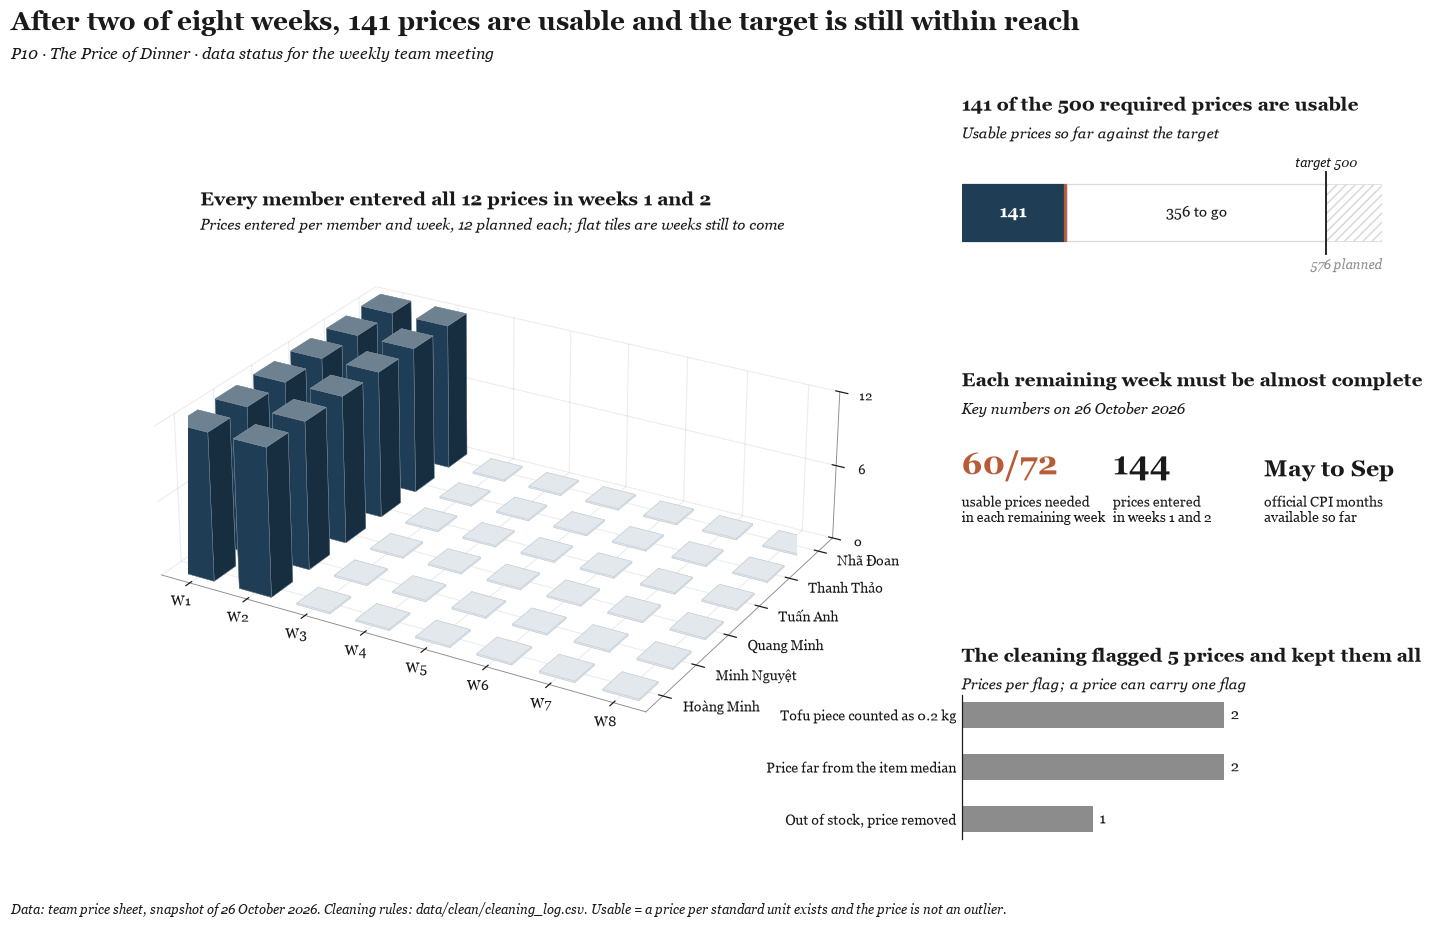

Prices entered per member and week:


week,1,2,3,4,5,6,7,8
assigned_to,,,,,,,,
Nguyễn Hoàng Minh,12,12,0,0,0,0,0,0
Nguyễn Minh Nguyệt,12,12,0,0,0,0,0,0
Phạm Quang Minh,12,12,0,0,0,0,0,0
Phạm Tuấn Anh,12,12,0,0,0,0,0,0
Trần Nguyễn Thanh Thảo,12,12,0,0,0,0,0,0
Trần Nhã Đoan,12,12,0,0,0,0,0,0


In [16]:
# M2.8 The data status figure: a 3D grid of prices per member and week, and three flat panels

# ---------------- numbers
PLANNED, TARGET, WEEKS = 576, 500, 8
grid = master.pivot_table(index="assigned_to", columns="week", values="collected", aggfunc="sum").reindex(columns=range(1, 9), fill_value=0)
grid = grid.loc[grid.sum(axis=1).sort_values().index]           # fewest prices in front
weeks_done = int((master.groupby("week")["collected"].sum() > 0).sum())
entered = int(master["collected"].sum())
usable = int(master["usable"].sum())
flagged = entered - usable
need_week = int(np.ceil((TARGET - usable) / (WEEKS - weeks_done)))
missing = [(r, w) for r in grid.index for w in range(1, weeks_done + 1) if grid.loc[r, w] < 12]
flag_counts = (master.loc[master["collected"], "flags"].fillna("").str.split(";").explode().replace("", np.nan).dropna().value_counts())
FLAG_NAMES = {"assumed_weight": "Tofu piece counted as 0.2 kg", "outlier": "Price far from the item median",
              "out_of_stock": "Out of stock, price removed", "unit_mismatch": "Unit does not fit the item"}

DONE, MISS = CHANNEL["Siêu thị"], HIGHLIGHT
fig = plt.figure(figsize=(14, 8.2))
gs = fig.add_gridspec(3, 2, width_ratios=[1.45, 1], height_ratios=[1, 1, 1.05], hspace=1.0, wspace=0.32)

# ---------------- A: 3D skyline of prices entered per member and week
ax = fig.add_subplot(gs[:, 0], projection="3d")
names = list(grid.index)
d = 0.56
bars = [(w - 1, i, grid.loc[n, w]) for i, n in enumerate(names) for w in range(1, weeks_done + 1) if grid.loc[n, w] > 0]
x, y, z = (np.array(v, dtype=float) for v in zip(*bars))
ax.bar3d(x - d / 2, y - d / 2, 0, d, d, z, color=sum((faces3d(DONE) for _ in bars), []), shade=False,
         edgecolor=tint(DONE, 0.5), linewidth=0.25)
plan = [(w - 1, i) for i in range(len(names)) for w in range(weeks_done + 1, 9)]
px, py = (np.array(v, dtype=float) for v in zip(*plan))
ax.bar3d(px - d / 2, py - d / 2, 0, d, d, 0.12, color="#E3E8ED", shade=False, edgecolor="#C9D2DA", linewidth=0.4)
for r, w in missing:
    ax.bar3d(w - 1 - d / 2, names.index(r) - d / 2, 0, d, d, 0.12, color=tint(MISS, 0.55), shade=False, edgecolor=MISS, linewidth=1.2)
ax.set_xticks(range(8), [f"W{w}" for w in range(1, 9)], fontsize=9)
ax.set_yticks(range(len(names)), [" ".join(n.split()[-2:]) for n in names], fontsize=9, ha="left", va="center")
ax.set_zticks([0, 6, 12], ["0", "6", "12"], fontsize=8.5)
ax.set_xlim(-0.5, 7.5); ax.set_ylim(-0.5, len(names) - 0.5); ax.set_zlim(0, 12)
ax.view_init(elev=26, azim=-60)
ax.set_box_aspect((8, 6, 2.4), zoom=1.12)
for a in (ax.xaxis, ax.yaxis, ax.zaxis):
    a.set_pane_color((1, 1, 1, 0)); a._axinfo["grid"]["color"] = (0, 0, 0, 0.07)
    a.line.set_color(GREY); a.line.set_linewidth(0.6)
ax.tick_params(axis="both", pad=0, colors=INK)
from mpl_toolkits.mplot3d import proj3d
for r, w in missing:   # 3D text is hidden behind the bars, so the label is drawn in 2D on top
    sx, sy, _ = proj3d.proj_transform(w - 1, names.index(r), 0.1, ax.get_proj())
    ax.annotate(f"{r.split()[-2]} {r.split()[-1]}: 0 of 12", xy=(sx, sy), xytext=(28, -26), textcoords="offset points",
                color=MISS, fontsize=10, fontweight="bold", zorder=10, bbox=dict(fc="white", ec="none", pad=1.5),
                arrowprops=dict(arrowstyle="-", color=MISS, lw=1, shrinkA=0, shrinkB=2))
if missing:
    grid_title = f"{len(missing)} member week{'s' if len(missing) > 1 else ''} still missing prices"
else:
    grid_title = "Every member entered all 12 prices in " + (f"weeks 1 and {weeks_done}" if weeks_done == 2 else f"weeks 1 to {weeks_done}")
ax.text2D(0.02, 0.97, grid_title, transform=ax.transAxes, fontsize=12.5, fontweight="bold")
ax.text2D(0.02, 0.93, "Prices entered per member and week, 12 planned each; flat tiles are weeks still to come",
          transform=ax.transAxes, fontsize=9.5, style="italic")

# ---------------- B: progress to 500
ax = fig.add_subplot(gs[0, 1])
parts = [(usable, DONE, f"{usable} usable"), (flagged, MISS, f"{flagged} flagged"),
         (TARGET - usable - flagged, "white", f"{TARGET - usable - flagged} still to collect")]
left = 0
for val, col, lab in parts:
    ax.barh(0, val, left=left, color=col, height=0.5, edgecolor=LIGHT if col == "white" else col, lw=0.8)
    left += val
ax.barh(0, PLANNED - TARGET, left=TARGET, color="white", height=0.5, edgecolor=LIGHT, hatch="////", lw=0.5)
ax.text(usable / 2, 0, f"{usable}", color="white", ha="center", va="center", fontsize=11, fontweight="bold")
ax.text(usable + flagged + (TARGET - usable - flagged) / 2, 0, f"{TARGET - usable - flagged} to go", ha="center", va="center", fontsize=10)
ax.plot([TARGET, TARGET], [-0.36, 0.36], color=INK, lw=1.2)
ax.text(TARGET, 0.4, "target 500", ha="center", fontsize=8.5, style="italic")
ax.text(PLANNED, -0.4, "576 planned", ha="right", va="top", fontsize=8.5, style="italic", color=GREY)
ax.set_xlim(0, PLANNED); ax.set_ylim(-0.6, 0.6); ax.axis("off")
title(ax, f"{usable} of the 500 required prices are usable", "Usable prices so far against the target")

# ---------------- C: key numbers
ax = fig.add_subplot(gs[1, 1]); ax.axis("off")
tiles = [(f"{need_week}/72", "usable prices needed\nin each remaining week"),
         (f"{entered}", "prices entered\nin weeks 1 and 2"),
         ("May to Sep", "official CPI months\navailable so far")]
for k, (big, small) in enumerate(tiles):
    x0 = k * 0.36
    ax.text(x0, 0.55, big, fontsize=21 if k < 2 else 15, fontweight="bold", color=MISS if k == 0 else INK, transform=ax.transAxes, va="bottom")
    ax.text(x0, 0.45, small, fontsize=9, transform=ax.transAxes, va="top")
title(ax, "Each remaining week must be almost complete", "Key numbers on " + SHEET_DATE)

# ---------------- D: flags
ax = fig.add_subplot(gs[2, 1])
fc = flag_counts.rename(index=FLAG_NAMES).sort_values()
ax.barh(fc.index, fc.values, color=GREY, height=0.5)
for i, v in enumerate(fc.values):
    ax.text(v + 0.05, i, f"{v}", va="center", fontsize=10)
ax.set_xlim(0, fc.max() * 1.6)
ax.spines[["bottom"]].set_visible(False); ax.set_xticks([]); ax.tick_params(axis="y", length=0)
title(ax, f"The cleaning flagged {int(flag_counts.sum())} prices and kept them all", "Prices per flag; a price can carry one flag")

figure_title(fig, f"After two of eight weeks, {usable} prices are usable and the target is still within reach",
             "P10 · The Price of Dinner · data status for the weekly team meeting", y=1.0)
note(fig, "Data: team price sheet, snapshot of " + SHEET_DATE + ". Cleaning rules: data/clean/cleaning_log.csv. "
          "Usable = a price per standard unit exists and the price is not an outlier.", y=0.04)
save(fig, FIG / "m2_data_status.png")
plt.show()
print("Prices entered per member and week:")
display(grid.astype(int))

### M2.9 · What my group learned from the first two weeks

1. **Quantities typed with a decimal point become dates.** The sheet uses the Vietnamese locale, so "2.5" turned
   into 2 May. My group will format the quantity column as plain number and ask members to type "2,5".
2. **Tofu needs one standard unit.** Members wrote tofu prices per piece, per 280 g pack and per kg. My group now
   uses kg and counts one piece as 0.2 kg, as the item specification says. A member will weigh one piece at each
   market in week 3 to check this assumption.
3. **An item that was out of stock still had a price.** The pipeline drops such prices; the sheet will get a reminder.
4. **The official CPI arrives one month late.** NSO releases a month's CPI in the first days of the next month,
   so the comparison in M4 can only use October and November 2026 for the eight weeks.
5. **Week 2 was completed late.** Twelve prices of week 2 (pork belly and beef) arrived on 26 October, after the first snapshot. The team now enters prices by Sunday evening.
6. **The 20% rule does not fit a team of six.** If each price has one collector, a full share is 16.7%. My group
   will ask the lecturer whether a price that two members collect together can carry both names.

---
# M3 · House style, colour check, makeover, honest and misleading pair
This module explains the house style that Setup wrote to `house_style.py`, tests it for colour vision and greyscale, redesigns a press chart and shows how the same numbers can mislead. The page `report/M3_style.md` repeats the text for the report.

In [17]:
usable_prices = master[master["usable"]]      # the usable rows of the master table from M2

### M3.1 · The house style on one page

My group fixed five rules so that every chart in the project looks the same.

1. **Channels have fixed colours, always in the same order:** wet market (terracotta), supermarket (dark blue),
   delivery app (light blue). The three colours also differ in lightness, so they work in greyscale.
2. **Districts never get a colour.** Quận 10 uses a solid line or a circle, and Quận 3 a dashed line or a square.
3. **Amounts use the sequential blue map. Changes use the diverging map** with its centre at 100 for an index or at 0
   for a percentage change. My group never uses a rainbow map.
4. **Charts are 3D columns** drawn with `bars3d()`: a light top, the base colour in front and darker sides. Three
   rules keep them honest: columns start at zero, the values that carry the finding are printed with `label3d()`,
   and the view stays low (about 20 degrees) so that the top of a column stays close to its value.
5. **Text:** a serif font, a bold title that states the finding, an italic subtitle with the units, labels next to
   the data, and a source line at the bottom. Prices appear as "45k" in charts and as "45,000 VND" in tables.

**From v0 to v1.** My group wrote a first house style (v0) in Task 0 of Group Homework 3. Version 1 changes three things. First, v0 gave the wet market blue, the supermarket orange and the app teal; v1 gives the wet market terracotta and both other channels a blue, so that the highlight colour of the project is also the cheapest channel. The greyscale test of M3.2 then made my group darken the supermarket blue once more. Second, v0 used the ready made maps cividis and RdBu_r; v1 builds both maps from the channel colours, so that the whole project uses one family of colours, and the diverging map keeps light and dark ends that stay apart in greyscale. Third, v1 adds the 3D column style and the helpers `bars3d`, `style3d`, `label3d` and `title3d`.

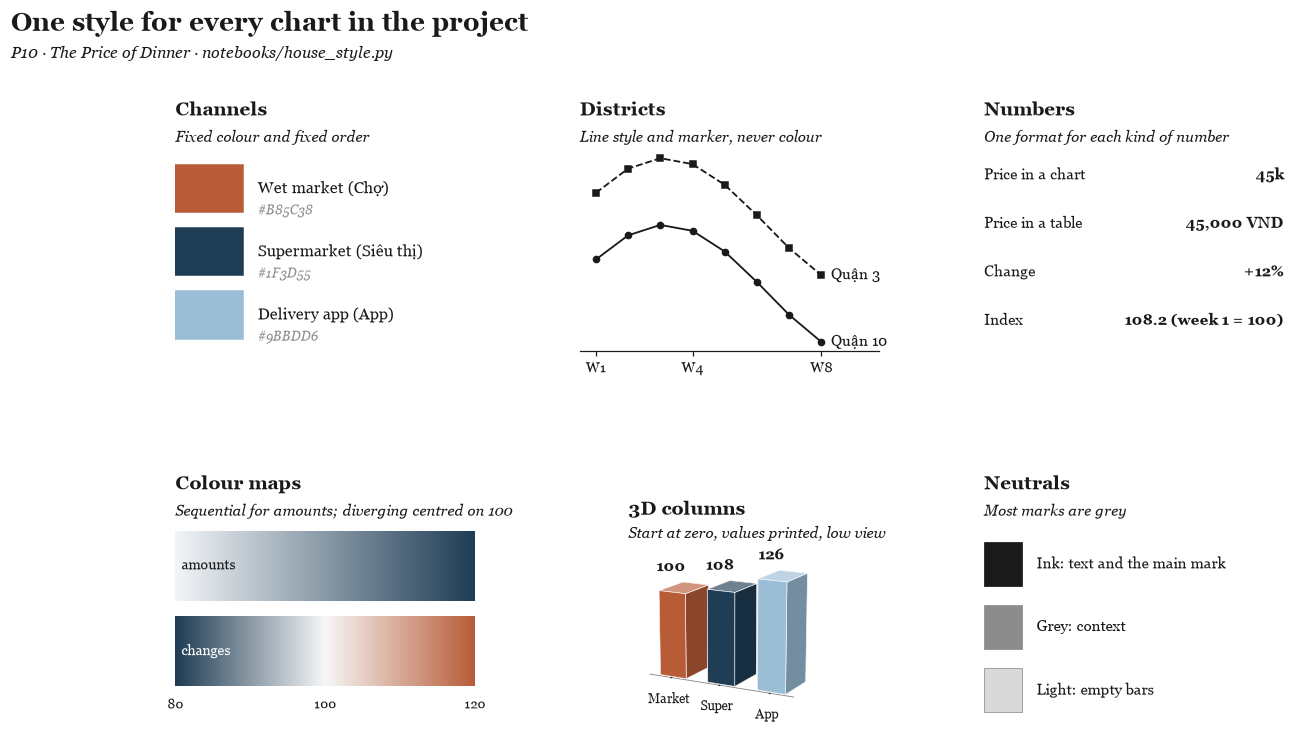

In [18]:
# M3.1 The house style on one page: colours, districts, numbers, colour maps, 3D columns and neutrals
fig = plt.figure(figsize=(13, 6.8))
gs = fig.add_gridspec(2, 3, hspace=0.85, wspace=0.35)

# A: channel colours
ax = fig.add_subplot(gs[0, 0]); ax.axis("off")
for i, ch in enumerate(CHANNEL_ORDER):
    ax.add_patch(plt.Rectangle((0, 2 - i), 0.9, 0.75, color=CHANNEL[ch]))
    ax.text(1.1, 2 - i + 0.37, f"{CHANNEL_EN[ch]} ({ch})", va="center", fontsize=10.5)
    ax.text(1.1, 2 - i + 0.02, CHANNEL[ch], va="center", fontsize=8.5, style="italic", color=GREY)
ax.set_xlim(0, 4); ax.set_ylim(-0.2, 3)
title(ax, "Channels", "Fixed colour and fixed order")

# B: districts
ax = fig.add_subplot(gs[0, 1])
x = np.arange(1, 9)
for d in DISTRICT_ORDER:
    y = 100 + (2 if d == "Quận 3" else 0) + np.sin(x / 2) * 2
    ax.plot(x, y, color=INK, ls=DISTRICT_LINE[d], marker=DISTRICT_MARKER[d], ms=4, lw=1.2)
    ax.text(8.3, y[-1], d, va="center", fontsize=9.5)
ax.set_xlim(0.5, 9.8); ax.set_xticks([1, 4, 8], ["W1", "W4", "W8"]); ax.set_yticks([])
ax.spines["left"].set_visible(False)
title(ax, "Districts", "Line style and marker, never colour")

# C: number formats
ax = fig.add_subplot(gs[0, 2]); ax.axis("off")
examples = [("Price in a chart", fmt_vnd(45000)), ("Price in a table", fmt_vnd(45000, short=False)),
            ("Change", fmt_pct(0.123, sign=True)), ("Index", "108.2 (week 1 = 100)")]
for i, (k, v) in enumerate(examples):
    ax.text(0, 0.85 - i * 0.24, k, fontsize=10, transform=ax.transAxes)
    ax.text(1, 0.85 - i * 0.24, v, fontsize=10, ha="right", fontweight="bold", transform=ax.transAxes)
title(ax, "Numbers", "One format for each kind of number")

# D: colour maps
ax = fig.add_subplot(gs[1, 0])
grad = np.linspace(0, 1, 256)[None, :]
ax.imshow(grad, aspect="auto", cmap=SEQ, extent=[0, 1, 0.55, 1])
ax.imshow(grad, aspect="auto", cmap=DIV, extent=[0, 1, 0, 0.45])
ax.text(0.02, 0.775, "amounts", va="center", fontsize=9, color=INK)
ax.text(0.02, 0.225, "changes", va="center", fontsize=9, color="white")
for xpos, lab in [(0, "80"), (0.5, "100"), (1, "120")]:
    ax.text(xpos, -0.08, lab, ha="center", va="top", fontsize=8.5)
ax.set_xlim(0, 1); ax.set_ylim(-0.25, 1.05); ax.axis("off")
title(ax, "Colour maps", "Sequential for amounts; diverging centred on 100")

# E: the 3D column style
ax = fig.add_subplot(gs[1, 1], projection="3d")
sample = [100, 108, 126]
bars3d(ax, range(3), [0] * 3, sample, [CHANNEL[c] for c in CHANNEL_ORDER], width=0.55, depth=0.55)
style3d(ax, elev=14, azim=-62, aspect=(3, 1, 2.2), zoom=1.0, zaxis=False, yaxis=False)
ax.set_xticks(range(3), ["Market", "Super", "App"], fontsize=8.5)
ax.set_zlim(0, 135)
for i, v in enumerate(sample):
    label3d(ax, i, -0.3, v, f"{v}", fontsize=9.5, fontweight="bold")
title3d(ax, "3D columns", "Start at zero, values printed, low view")

# F: neutrals
ax = fig.add_subplot(gs[1, 2]); ax.axis("off")
for i, (name, c) in enumerate([("Ink: text and the main mark", INK), ("Grey: context", GREY), ("Light: empty bars", LIGHT)]):
    ax.add_patch(plt.Rectangle((0, 2 - i), 0.5, 0.7, color=c, ec=GREY if c == LIGHT else c, lw=0.5))
    ax.text(0.7, 2 - i + 0.35, name, va="center", fontsize=9.5)
ax.set_xlim(0, 4); ax.set_ylim(-0.2, 3)
title(ax, "Neutrals", "Most marks are grey")

figure_title(fig, "One style for every chart in the project", "P10 · The Price of Dinner · notebooks/house_style.py", y=1.03)
save(fig, FIG / "m3_house_style.png")
plt.show()

### M3.2 · Colour vision and greyscale check

My group checks the palette in two ways.

* **Numbers.** `cvd_report()` simulates protanopia, deuteranopia and tritanopia with the matrices of Machado,
  Oliveira and Fernandes (2009) and converts the result to greyscale. It then measures the smallest colour
  difference (CIE76 ΔE) between any two channel colours. A ΔE above about 20 is easy to see on a screen.
* **Pictures.** The notebook draws one real 3D chart five times, once for each type of vision: the median price index of the three channels. Each panel holds only three columns, so the reader compares colours and nothing else.

In [19]:
report = pd.Series(cvd_report(CHANNEL)).rename("smallest ΔE between two channel colours").round(1)
report.to_frame()

,smallest ΔE between two channel colours
normal,50.5
protan,50.4
deutan,50.4
tritan,50.1
greyscale,25.1


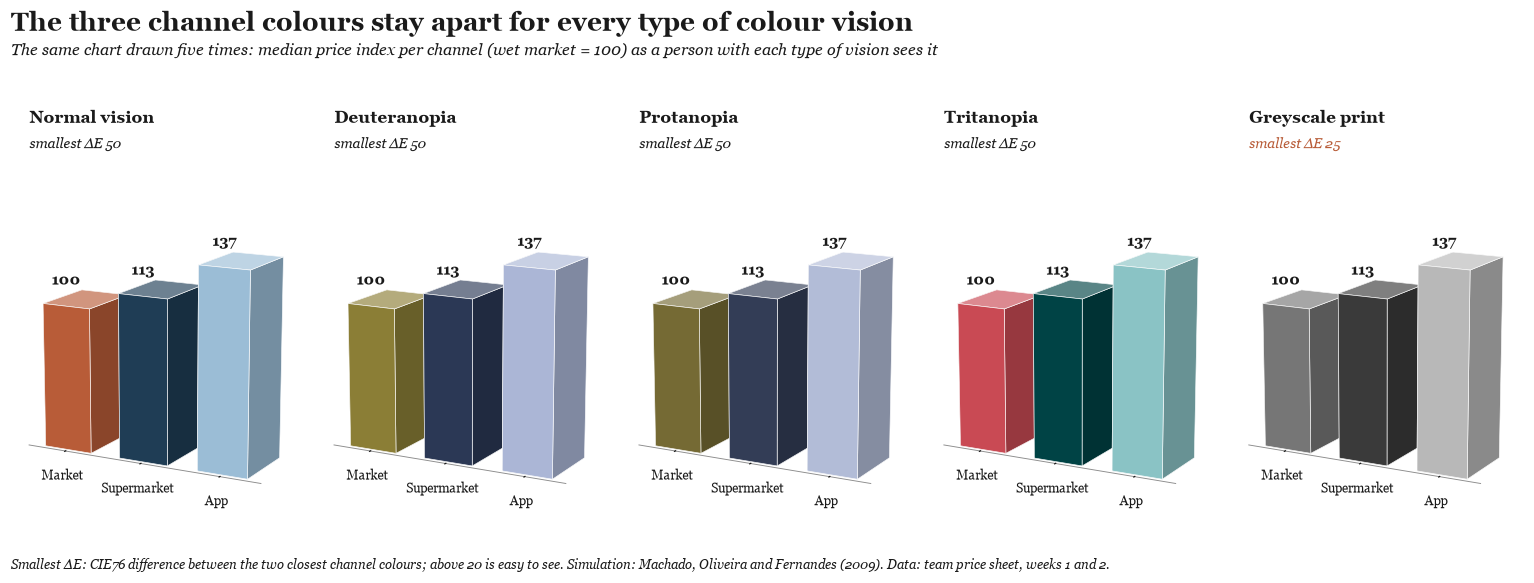

Median price index per channel: {'Chợ': 100.0, 'Siêu thị': 113.0, 'App': 137.0}


In [20]:
# M3.2 One real 3D chart (median price index per channel) as seen with each type of colour vision
item_avg = usable_prices.groupby(["item_code", "channel"])["price_std"].mean().unstack()[CHANNEL_ORDER]
idx = (item_avg.div(item_avg["Chợ"], axis=0) * 100).median()[CHANNEL_ORDER]
KINDS = [("normal", "Normal vision"), ("deutan", "Deuteranopia"), ("protan", "Protanopia"),
         ("tritan", "Tritanopia"), ("greyscale", "Greyscale print")]
SHORT_EN = {"Chợ": "Market", "Siêu thị": "Super-\nmarket", "App": "App"}

fig = plt.figure(figsize=(14, 4.6))
w = 0.19
for j, (kind, label) in enumerate(KINDS):
    x0 = 0.01 + j * 0.198
    ax = fig.add_axes([x0, 0.0, w, 0.8], projection="3d")
    cols = [to_hex(simulate(CHANNEL[c], kind)) for c in CHANNEL_ORDER]
    bars3d(ax, range(3), [0] * 3, idx.values, cols, width=0.62, depth=0.62)
    style3d(ax, elev=14, azim=-62, aspect=(3, 1, 2.4), zoom=1.15, zaxis=False, yaxis=False)
    ax.set_zlim(0, 140)
    ax.set_xticks(range(3), [SHORT_EN[c].replace("-\n", "") for c in CHANNEL_ORDER], fontsize=8.5)
    for i, v in enumerate(idx.values):
        label3d(ax, i, -0.31, v, f"{v:.0f}", fontsize=10, fontweight="bold")
    fig.text(x0 + 0.012, 0.86, label, fontsize=11, fontweight="bold", ha="left")
    fig.text(x0 + 0.012, 0.81, f"smallest ΔE {report[kind]:.0f}", fontsize=9, style="italic", ha="left",
             color=HIGHLIGHT if report[kind] < 30 else INK)
figure_title(fig, "The three channel colours stay apart for every type of colour vision",
             "The same chart drawn five times: median price index per channel (wet market = 100) as a person with each type of vision sees it", y=1.03)
note(fig, "Smallest ΔE: CIE76 difference between the two closest channel colours; above 20 is easy to see. "
          "Simulation: Machado, Oliveira and Fernandes (2009). Data: team price sheet, weeks 1 and 2.", y=0.0)
save(fig, FIG / "m3_cvd_check.png")
plt.show()
print("Median price index per channel:", idx.round(0).to_dict())

**What my group concludes.** Under the three colour vision simulations, the smallest difference stays above 45 ΔE.
Greyscale is the hardest case, with about 25 ΔE between the supermarket and the wet market, which is still above
the guide value of 20. In greyscale the three colours keep their order from dark to light (supermarket, wet market,
app), so a printed report stays readable.

My group changed the palette once because of this check. The first version used a lighter supermarket blue
(#2C4F6B) and a darker app blue (#8FB3CF). That version passed all three colour vision tests, but in greyscale the
wet market and the supermarket were only 17 ΔE apart. A darker supermarket blue and a lighter app blue fixed it. My group still writes the channel name next to the marks in every final chart, so no reader
has to rely on colour alone.

### M3.3 · Makeover of a press chart about inflation
**The original.** My group chose Figure 5 on page 13 of the report *Tổng quan thị trường giá cả tháng 9, quý III và 9 tháng năm 2026* (Overview of prices in September, the third quarter and the first nine months of 2026) by the Cục Thống kê (National Statistics Office, Ministry of Finance). The report is dated 30 September 2026 and was published on 3 October 2026 with the [press release](https://www.nso.gov.vn/tin-tuc-thong-ke/2026/10/thong-cao-bao-chi-ve-tinh-hinh-gia-thang-chin-quy-iii-va-9-thang-nam-2026/). My group read the report on 19 October 2026 through this [PDF](https://www.nso.gov.vn/wp-content/uploads/2026/10/Tong-quan-CPI-chi-so-gia-vang-do-la-My-thang-9-QIII-va-9-thang-nam-2026.pdf). My group first planned this makeover in Group Homework 3.

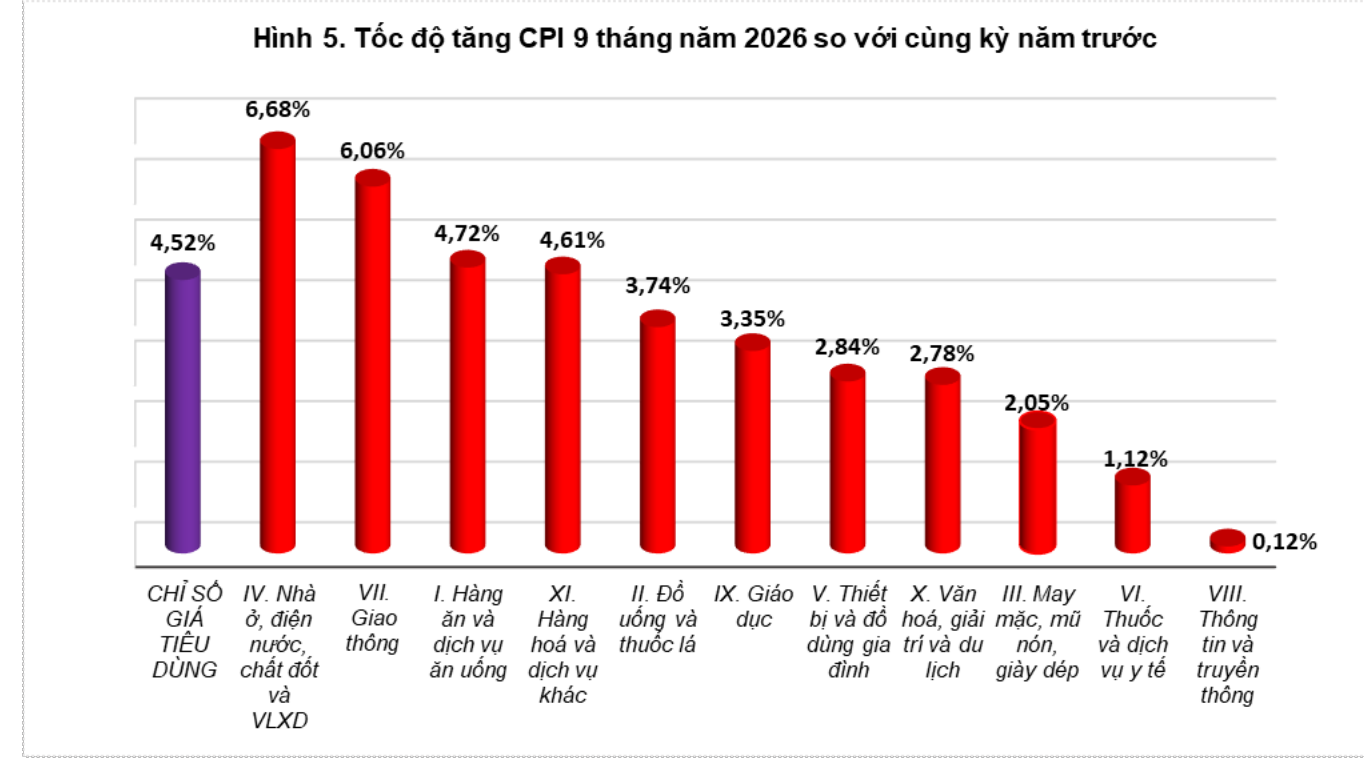

Figure 5 shows how much the prices of each of the 11 groups of goods and services rose in the first nine months of 2026, compared with the same months of 2025. The text under the chart asks which groups pushed the CPI up, so my group takes that as the task of the chart.

| # | What my group sees | Principle broken | Effect on the reader | My group's fix |
|---|---|---|---|---|
| 1 | Every bar is a shaded 3D cylinder with an oval top, and the smallest group (0.12%) appears only as a red disc | Data ink and expressiveness | The reader has to judge where an oval top ends, and the 0.12% group looks like a blob instead of a bar that is almost zero | Flat bars on a common baseline at zero |
| 2 | The national CPI (4.52%) is one more bar, in purple, at the left end of the row of groups | Gestalt similarity and expressiveness | The reader takes the average for a twelfth group and has to compare every red bar with a purple bar far away | A reference line at 4.52% across all the groups |
| 3 | All eleven groups have the same strong red | Colour job and preattentive attention | Red signals danger for every group, so no group stands out | All groups grey, and one colour for food and catering, the group that our project studies |
| 4 | The labels carry Roman numerals and wrap over up to five lines in small italics | Short term memory and effectiveness | The reader has to decode codes such as IV. and XI. and read five short lines under each narrow bar | Horizontal bars with short names on one line |
| 5 | The chart has gridlines, but the axis has no numbers | Data ink | The gridlines cannot be read, so they add clutter | No gridlines, and a value label on every bar |
| 6 | The chart shows only how fast prices rose; the text says that food and catering added the most to the CPI (1.69 percentage points) | Expressiveness: the chart does not fit the task | The reader concludes that housing and transport drove inflation | A second panel that shows how many points each group added to the CPI |

**Why this redesign stays flat.** Every other chart of the project uses the 3D column style of M3.1. The makeover is the one exception: the first problem that my group names in the original is its 3D cylinders, so a 3D redesign would repeat the error that the critique describes.

**The hand sketch** that my group drew before coding the redesign:

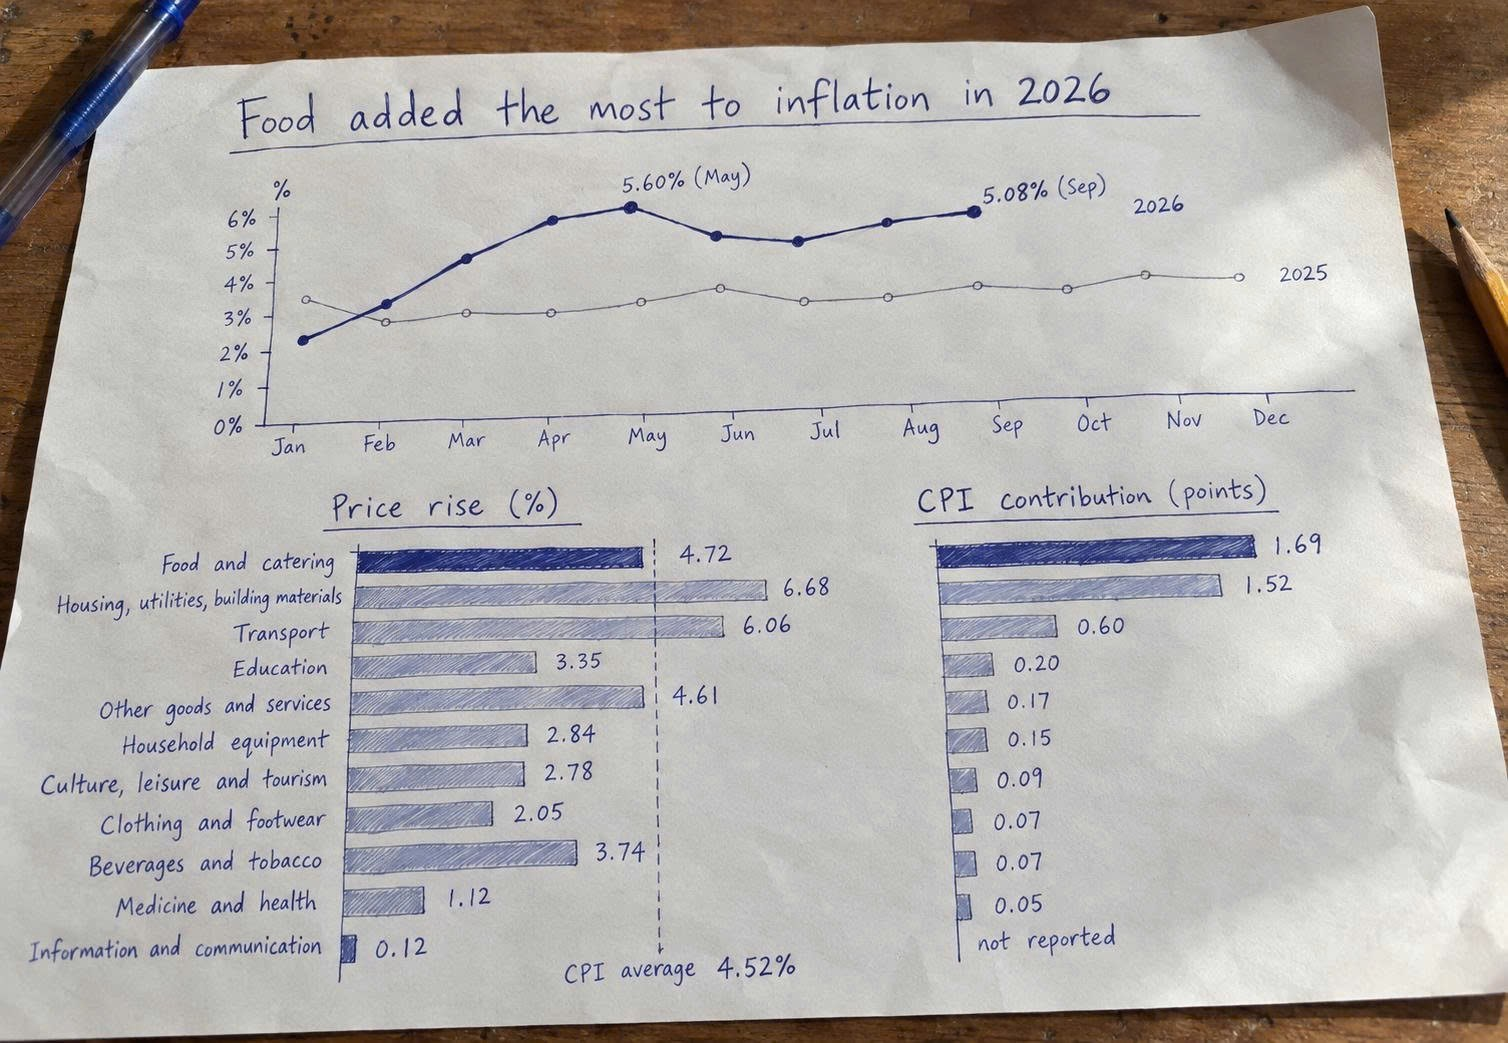

In [21]:
# M3.3 The numbers of the redesign, typed from the NSO report: monthly CPI rates (Figure 4, page 12),
# group rates (Figure 5, page 13) and contributions to the CPI (text on pages 13 and 14)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
cpi_2025 = [3.63, 2.91, 3.13, 3.12, 3.24, 3.57, 3.19, 3.24, 3.38, 3.25, 3.58, 3.48]   # % against the same month of 2024
cpi_2026 = [2.53, 3.35, 4.65, 5.46, 5.60, 4.69, 4.45, 4.88, 5.08]                     # % against the same month of 2025
CPI_9M = 4.52                                                                         # average of January to September 2026, %
groups = pd.DataFrame({
    "group": ["Housing, utilities, building materials", "Transport", "Food and catering",
              "Other goods and services", "Beverages and tobacco", "Education", "Household equipment",
              "Culture, leisure and tourism", "Clothing and footwear", "Medicine and health",
              "Information and communication"],
    "rate": [6.68, 6.06, 4.72, 4.61, 3.74, 3.35, 2.84, 2.78, 2.05, 1.12, 0.12],
    "points": [1.52, 0.60, 1.69, 0.17, 0.07, 0.20, 0.15, 0.09, 0.07, 0.05, np.nan],
}).sort_values("points", na_position="first").reset_index(drop=True)
FOCUS = "Food and catering"
food = groups.set_index("group").loc[FOCUS]
months_above = [MONTHS[i] for i in range(len(cpi_2026)) if cpi_2026[i] > cpi_2025[i]]
print("Groups that rose faster than food:", groups.loc[groups["rate"] > food["rate"], "group"].tolist())
print("Largest contribution:", groups.loc[groups["points"].idxmax(), "group"], groups["points"].max(), "points")
print("Months of 2026 above the same month of 2025:", months_above)

Groups that rose faster than food: ['Transport', 'Housing, utilities, building materials']
Largest contribution: Food and catering 1.69 points
Months of 2026 above the same month of 2025: ['Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep']


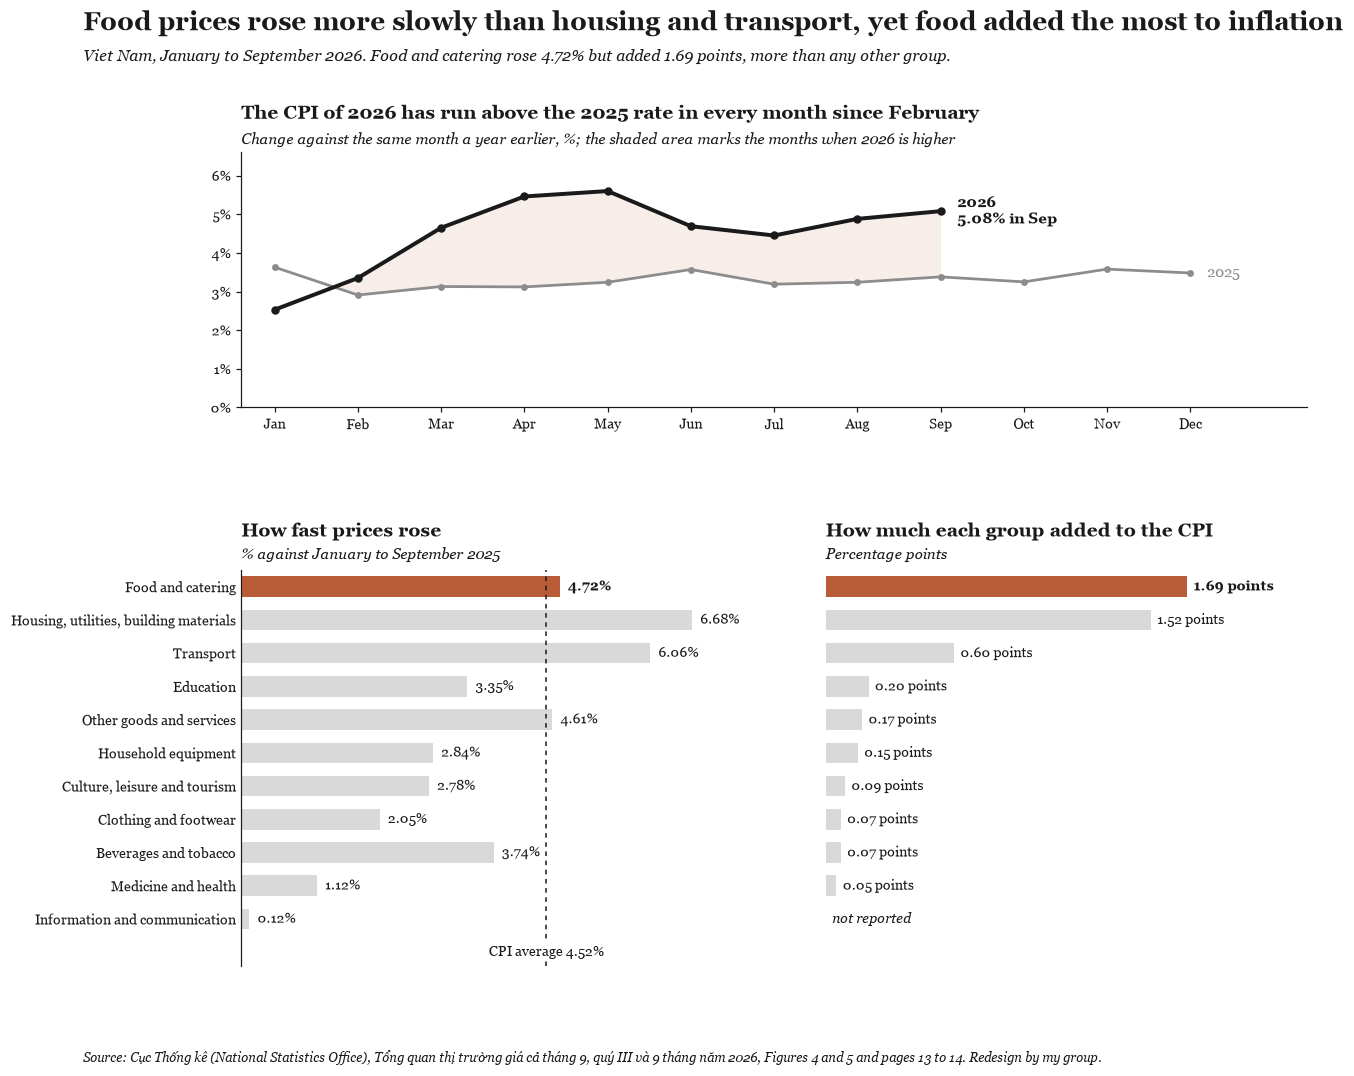

In [22]:
# M3.3 The redesign: the CPI month by month on top, and two aligned bar panels for the groups below
fig = plt.figure(figsize=(12.5, 9.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.55], width_ratios=[1.15, 1], hspace=0.5, wspace=0.06)
ax_m, ax_r = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0])
ax_p = fig.add_subplot(gs[1, 1], sharey=ax_r)

x25, x26 = np.arange(12), np.arange(len(cpi_2026))
ax_m.fill_between(x26, cpi_2025[:len(x26)], cpi_2026, where=np.array(cpi_2026) > np.array(cpi_2025[:len(x26)]),
                  interpolate=True, color=HIGHLIGHT, alpha=0.10, lw=0)
ax_m.plot(x25, cpi_2025, color=GREY, lw=1.8, marker="o", ms=3.5)
ax_m.plot(x26, cpi_2026, color=INK, lw=2.6, marker="o", ms=4.5)
ax_m.text(11.2, cpi_2025[-1], "2025", va="center", color=GREY, fontsize=10)
ax_m.text(x26[-1] + 0.2, cpi_2026[-1], f"2026\n{cpi_2026[-1]:.2f}% in Sep", va="center", fontsize=10, fontweight="bold")
ax_m.set_xticks(x25, MONTHS); ax_m.set_xlim(-0.4, 12.4); ax_m.set_ylim(0, 6.6)
ax_m.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
title(ax_m, "The CPI of 2026 has run above the 2025 rate in every month since February",
      "Change against the same month a year earlier, %; the shaded area marks the months when 2026 is higher")

colors = [HIGHLIGHT if g == FOCUS else LIGHT for g in groups["group"]]
y = np.arange(len(groups))
ax_r.barh(y, groups["rate"], color=colors, height=0.62)
ax_r.axvline(CPI_9M, color=INK, lw=1, ls=(0, (3, 3)))
ax_r.text(CPI_9M, -0.8, f"CPI average {CPI_9M:.2f}%", ha="center", va="top", fontsize=9,
          bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
for yi, (g, r) in enumerate(zip(groups["group"], groups["rate"])):
    ax_r.text(r + 0.12, yi, f"{r:.2f}%", va="center", fontsize=9, fontweight="bold" if g == FOCUS else "normal")
ax_r.set_yticks(y, groups["group"]); ax_r.set_ylim(-1.4, len(groups) - 0.5); ax_r.set_xlim(0, 8.2)
ax_r.set_xticks([]); ax_r.spines["bottom"].set_visible(False); ax_r.tick_params(axis="y", length=0)
title(ax_r, "How fast prices rose", "% against January to September 2025")

ax_p.barh(y, groups["points"].fillna(0), color=colors, height=0.62)
for yi, (g, p) in enumerate(zip(groups["group"], groups["points"])):
    ax_p.text((0 if np.isnan(p) else p) + 0.03, yi, "not reported" if np.isnan(p) else f"{p:.2f} points",
              va="center", fontsize=9, style="italic" if np.isnan(p) else "normal", fontweight="bold" if g == FOCUS else "normal")
ax_p.set_xlim(0, 2.25); ax_p.set_xticks([]); ax_p.spines[["bottom", "left"]].set_visible(False)
ax_p.tick_params(axis="y", length=0, labelleft=False)
title(ax_p, "How much each group added to the CPI", "Percentage points")

figure_title(fig, "Food prices rose more slowly than housing and transport, yet food added the most to inflation",
             f"Viet Nam, January to September 2026. Food and catering rose {food['rate']:.2f}% but added {food['points']:.2f} points, more than any other group.",
             y=0.99)
note(fig, "Source: Cục Thống kê (National Statistics Office), Tổng quan thị trường giá cả tháng 9, quý III và 9 tháng năm 2026, "
          "Figures 4 and 5 and pages 13 to 14. Redesign by my group.", y=0.03)
save(fig, FIG / "m3_makeover_redesign.png")
plt.show()

**Makeover text (150 words).** The original Figure 5 draws eleven CPI groups as red 3D cylinders and the national average as a purple bar beside them. The 3D shading breaks the data ink principle, because the reader must guess where each oval top ends, and the purple bar breaks Gestalt similarity, because it looks like a twelfth group. The chart also fails its task: the text asks which groups pushed the CPI up, but the bars show only how fast prices rose. My group redrew it with flat horizontal bars on a zero baseline and the average as a dashed line. A second aligned panel shows how many points each group added to the CPI. Food and catering is the only coloured group, and the title states the finding: food prices rose more slowly than housing and transport, yet food added the most to inflation, because it weighs most in the basket.

### M3.4 · Honest and misleading pair
Both charts show the same three numbers: the cost of one basket of our twelve items in each channel. The basket holds 1 kg of each item sold by weight, 1 kg of tofu and 10 eggs, at the average price of weeks 1 and 2 in both districts. Both charts use the 3D column style of the project, so the pair shows exactly which choices turn the same style from honest into misleading.

In [23]:
QTY = {code: 1.0 for code in master["item_code"].unique()}
QTY["SP11"] = 10                       # eggs are priced per egg
item_avg = usable_prices.groupby(["item_code", "channel"])["price_std"].mean().unstack()[CHANNEL_ORDER]
basket = item_avg.mul(pd.Series(QTY), axis=0).sum()
premium = basket / basket["Chợ"] - 1
pd.DataFrame({"basket_vnd": basket.round(-3), "vs_wet_market": premium.map(lambda v: fmt_pct(v, 0, sign=True))})

,basket_vnd,vs_wet_market
channel,,
Chợ,1083000.0,+0%
Siêu thị,1169000.0,+8%
App,1392000.0,+28%


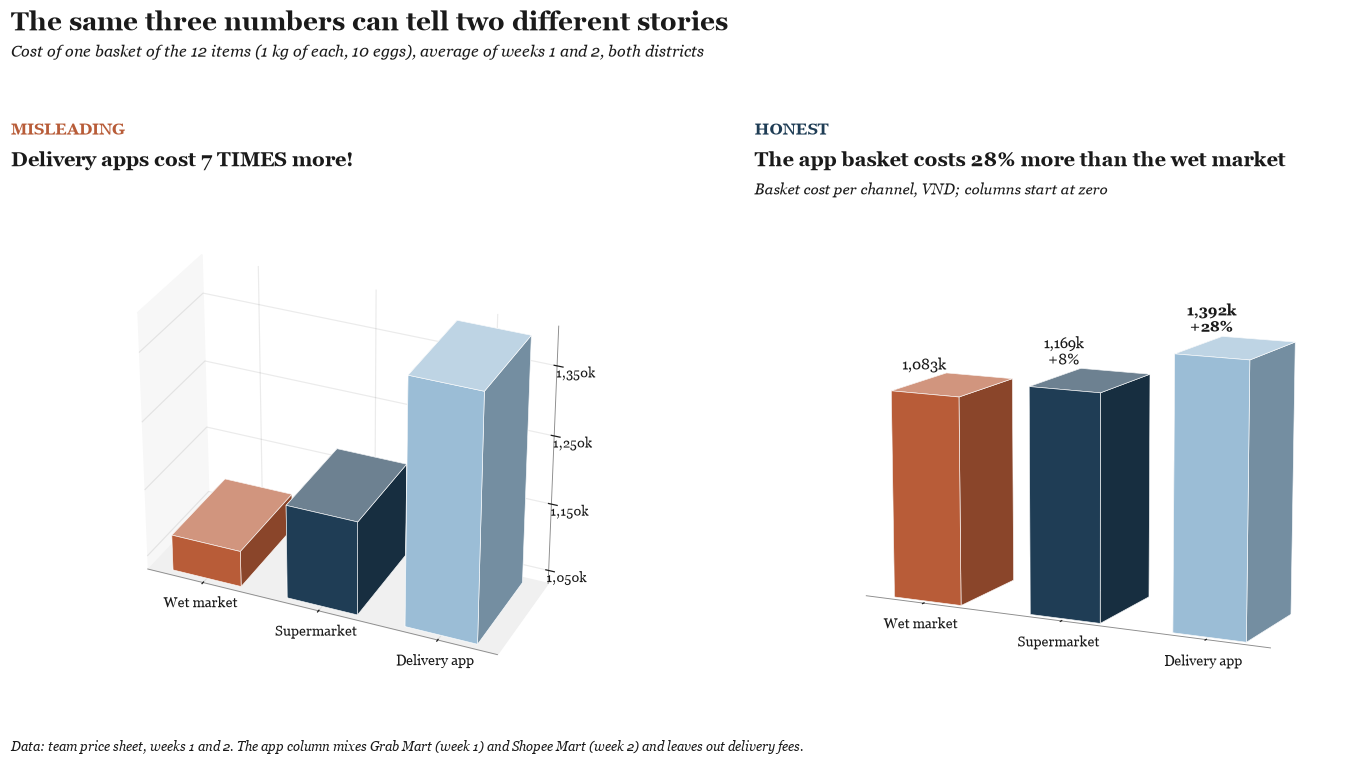

Misleading chart: the app column is 6.8 times as tall as the wet market column above the cut. Real ratio: 1.28.


In [24]:
# M3.4 The same basket costs drawn twice in 3D: misleading (cut axis, steep view, no values) and honest
low = np.floor(basket.min() / 50_000) * 50_000 - 20_000
ratio_bars = (basket["App"] - low) / (basket["Chợ"] - low)
colors = [CHANNEL[c] for c in CHANNEL_ORDER]
names = [CHANNEL_EN[c] for c in CHANNEL_ORDER]
fig = plt.figure(figsize=(13, 6.4))

fig.text(0.01, 0.86, "MISLEADING", fontsize=10.5, fontweight="bold", color=HIGHLIGHT)
fig.text(0.01, 0.815, f"Delivery apps cost {ratio_bars:.0f} TIMES more!", fontsize=13, fontweight="bold")
a1 = fig.add_axes([0.0, 0.02, 0.48, 0.76], projection="3d")
bars3d(a1, range(3), [0] * 3, basket.values, colors, width=0.6, depth=0.6, base=low)
style3d(a1, elev=30, azim=-66, aspect=(3, 1.1, 2.3), zoom=0.92, grid=True, yaxis=False)
a1.zaxis.set_pane_color((0.94, 0.94, 0.94, 1)); a1.xaxis.set_pane_color((0.97, 0.97, 0.97, 1))
a1.set_zlim(low, basket.max() * 1.01)
a1.set_zticks(np.arange(1_050_000, basket.max(), 100_000))
a1.zaxis.set_major_formatter(lambda v, _: fmt_vnd(v))
a1.set_xticks(range(3), names, fontsize=9)

fig.text(0.53, 0.86, "HONEST", fontsize=10.5, fontweight="bold", color=CHANNEL["Siêu thị"])
fig.text(0.53, 0.815, f"The app basket costs {fmt_pct(premium['App'])} more than the wet market", fontsize=13, fontweight="bold")
fig.text(0.53, 0.775, "Basket cost per channel, VND; columns start at zero", fontsize=9.5, style="italic")
a2 = fig.add_axes([0.52, 0.02, 0.48, 0.72], projection="3d")
XH = [0, 1.45, 2.9]
bars3d(a2, XH, [0] * 3, basket.values, colors, width=0.72, depth=0.6)
style3d(a2, elev=12, azim=-64, aspect=(3.4, 1, 2.2), zoom=1.05, zaxis=False, yaxis=False)
a2.set_zlim(0, basket.max() * 1.05)
a2.set_xticks(XH, names, fontsize=9)
for i, c in enumerate(CHANNEL_ORDER):
    txt = fmt_vnd(basket[c]) + ("" if c == "Chợ" else f"\n{fmt_pct(premium[c], 0, sign=True)}")
    label3d(a2, XH[i], -0.31, basket[c], txt, dy=14, fontsize=10, fontweight="bold" if c == "App" else "normal")

figure_title(fig, "The same three numbers can tell two different stories",
             "Cost of one basket of the 12 items (1 kg of each, 10 eggs), average of weeks 1 and 2, both districts", y=1.0)
note(fig, "Data: team price sheet, weeks 1 and 2. The app column mixes Grab Mart (week 1) and Shopee Mart (week 2) and leaves out delivery fees.", y=0.0)
save(fig, FIG / "m3_honest_vs_misleading.png")
plt.show()
print(f"Misleading chart: the app column is {ratio_bars:.1f} times as tall as the wet market column above the cut. "
      f"Real ratio: {basket['App'] / basket['Chợ']:.2f}.")

**How the misleading chart misleads.** It uses three tricks at once. First, the value axis starts at about 1,030,000 VND instead of zero, so the reader compares only the tops of the columns, and a gap of 28% looks like a gap of more than 500%. Second, the steep view tilts the columns, so the top of each column sits far from its value on the axis. Third, no value is printed, so the reader has nothing to check the picture against. The shouting title repeats the false ratio. In Tufte's terms, the Lie Factor is far above 1.

**How a reader can spot it.** The reader checks the lowest number on the value axis. If it is not zero, the column heights do not show the values. A tilted 3D chart without printed values is a second warning sign.

**What the honest chart does.** It keeps the same 3D style but starts the columns at zero, uses a low view, prints the money and the percentage gap on each column, and states the real size of the gap in the title. The app basket still leaves out the delivery fee, about 29,000 VND per order in weeks 1 and 2; Module M4 will add it.

---
# M4 · Core charts that answer the four questions
**What the brief asks.** At least six charts, one for each task, with at least five different idioms. Each chart starts with three lines: the task, why the idiom fits, and the action title. Every chart is sketched by hand before coding (photos in `evidence/sketches/`). Four charts are required: a dot plot of channel prices by item, a line chart of the basket cost per channel over the weeks, a bar chart of the channel premium, and a two panel chart that compares our index with the CPI (no dual axis). One chart goes through an AI audit.

**Status.** The data cover two of eight weeks, so my group drew two charts as a first draft. Both titles will change when all eight weeks are in.

| Chart | Task (Section M1.2) | Idiom | Status |
|---|---|---|---|
| 1 | Compare the price per kg across the three channels for each item | 3D column grid (replaces the dot plot of the brief; see M4.1) | Draft below |
| 2 | Rank the channels by their premium over the wet market | 3D columns | Draft below |
| 3 | Track the basket cost per channel week by week | Line | Needs at least four weeks |
| 4 | Compare our price index with the NSO food CPI | Two panels on one time axis | Needs the October CPI (early November) |
| 5 | Compare the two districts for each item and channel | Dumbbell | To do |
| 6 | Estimate the weekly basket cost for three personas | Stacked bar | Needs the survey |
| AI audit | One chart above, given to an AI tool | Prompt, raw output, at least three errors, fix | To do |

### M4.1 · Chart 1 (draft): channel prices by item
*Task:* compare the price per kg across the three channels for each of the 12 items.
*Why this chart:* A grid of 3D columns, with the items along one axis and the three channels along the other, shows all 36 prices at once. My group shows each price as an index with the wet market at 100, because the items differ in price by a factor of one hundred (an egg against a kilogram of mackerel). The wet market row stands in front, the supermarket in the middle and the app at the back, so the cheaper rows never hide the dearer ones.
*Choices:* Items run from the largest app premium on the left to the smallest on the right. The app values are printed on top of the back row, and the full table is printed below the chart.

Delivery app dearest in 11 of 12 items; wet market cheapest in 11 of 12 items


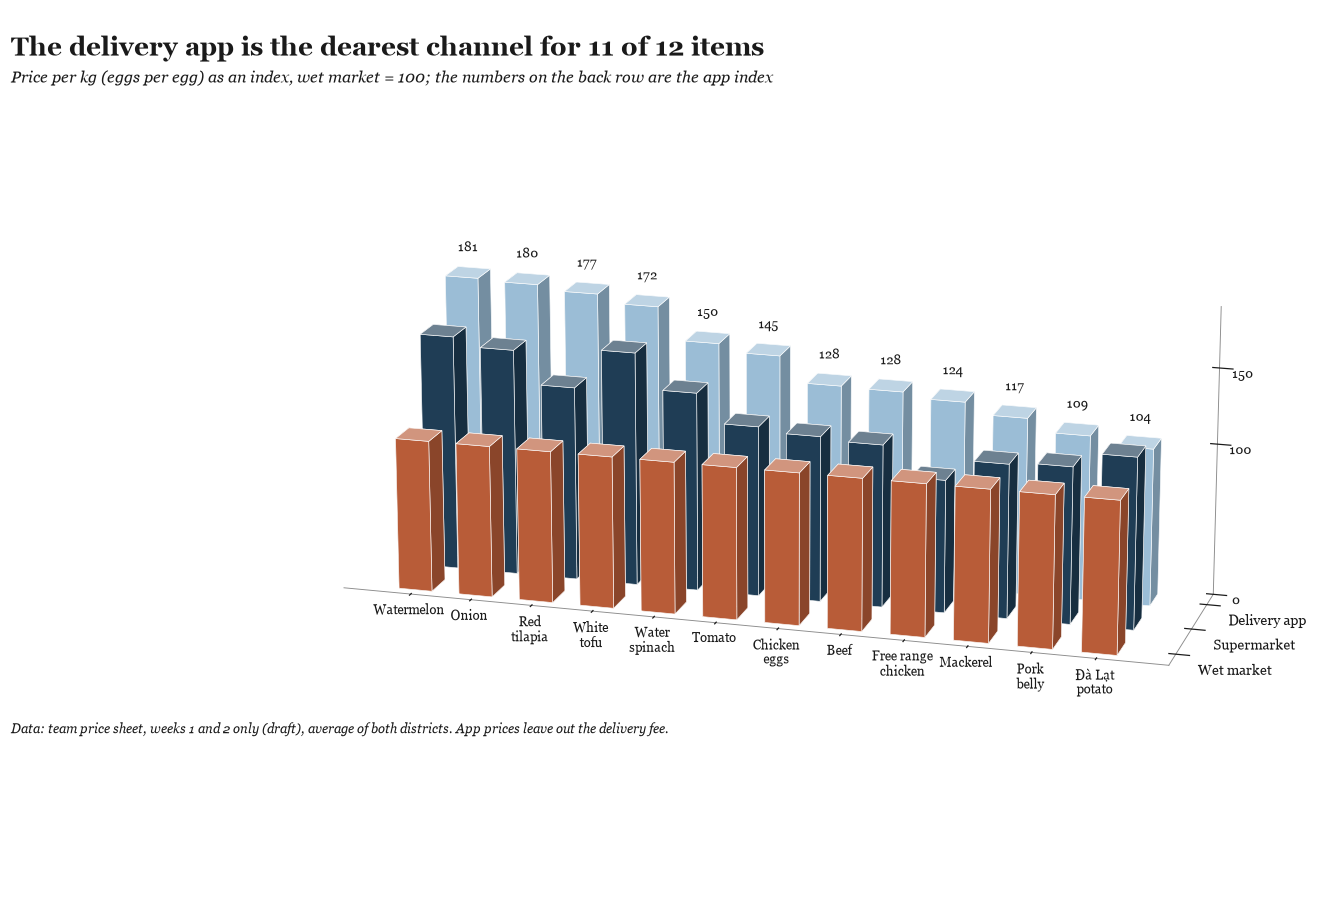

channel,Chợ,Siêu thị,App
item_code,,,
Watermelon,100.0,155.357143,181.428571
Onion,100.0,149.634146,180.182927
Red tilapia,100.0,127.999273,176.969091
White tofu,100.0,154.212454,171.550672
Water spinach,100.0,131.041667,150.208333
Tomato,100.0,112.231405,145.23416
Chicken eggs,100.0,109.183673,128.469388
Beef,100.0,107.10381,127.857143
Free range chicken,100.0,87.406015,124.43609


In [25]:
# M4.1 Relative price of each item per channel, wet market = 100, average of weeks 1 and 2 and both districts
ITEM_EN = {"SP01": "Pork belly", "SP02": "Water spinach", "SP03": "Mackerel", "SP04": "Tomato", "SP05": "Beef",
           "SP06": "Free range chicken", "SP07": "Watermelon", "SP08": "Onion", "SP09": "Đà Lạt potato",
           "SP10": "White tofu", "SP11": "Chicken eggs", "SP12": "Red tilapia"}
SHORT = {"Red tilapia": "Red\ntilapia", "White tofu": "White\ntofu", "Water spinach": "Water\nspinach",
         "Chicken eggs": "Chicken\neggs", "Free range chicken": "Free range\nchicken", "Pork belly": "Pork\nbelly",
         "Đà Lạt potato": "Đà Lạt\npotato"}
rel = item_avg.div(item_avg["Chợ"], axis=0) * 100
rel = rel.rename(index=ITEM_EN).sort_values("App", ascending=False)
n_app_dearest = int((rel["App"] > rel[["Chợ", "Siêu thị"]].max(axis=1)).sum())
n_market_cheapest = int((rel["Chợ"] <= rel[["Siêu thị", "App"]].min(axis=1)).sum())
print(f"Delivery app dearest in {n_app_dearest} of 12 items; wet market cheapest in {n_market_cheapest} of 12 items")

fig = plt.figure(figsize=(14, 6.6))
ax = fig.add_axes([-0.1, -0.2, 1.2, 1.24], projection="3d")
xs, ys, hs, cs = [], [], [], []
for i, item in enumerate(rel.index):
    for j, ch in enumerate(CHANNEL_ORDER):
        xs.append(i); ys.append(j); hs.append(rel.loc[item, ch]); cs.append(CHANNEL[ch])
bars3d(ax, xs, ys, hs, cs, width=0.55, depth=0.5)
style3d(ax, elev=17, azim=-74, aspect=(6.5, 1.7, 2.3), zoom=1.0)
ax.set_xticks(range(len(rel)), [SHORT.get(n, n) for n in rel.index], fontsize=8.5, ha="center", va="top")
ax.set_yticks(range(3), [CHANNEL_EN[c] for c in CHANNEL_ORDER], fontsize=9, ha="left")
ax.set_zticks([0, 100, 150], ["0", "100", "150"]); ax.set_zlim(0, 190)
for i, item in enumerate(rel.index):
    label3d(ax, i, 2, rel.loc[item, "App"], f"{rel.loc[item, 'App']:.0f}", fontsize=8.5, color=INK)
figure_title(fig, f"The delivery app is the dearest channel for {n_app_dearest} of 12 items",
             "Price per kg (eggs per egg) as an index, wet market = 100; the numbers on the back row are the app index", y=0.97)
note(fig, "Data: team price sheet, weeks 1 and 2 only (draft), average of both districts. App prices leave out the delivery fee.", y=0.06)
save(fig, FIG / "m4_chart1_channel_prices.png")
plt.show()
display(rel.round(0))

#### M4.1b · The dot plot that the brief requires
The brief asks for a dot plot of the channel prices by item, so my group keeps it next to the 3D grid. It shows the same index. In the dot plot the reader compares positions on one line, which is more exact; in the 3D grid the reader sees the whole pattern at once. Module M8 will test which version readers use better.

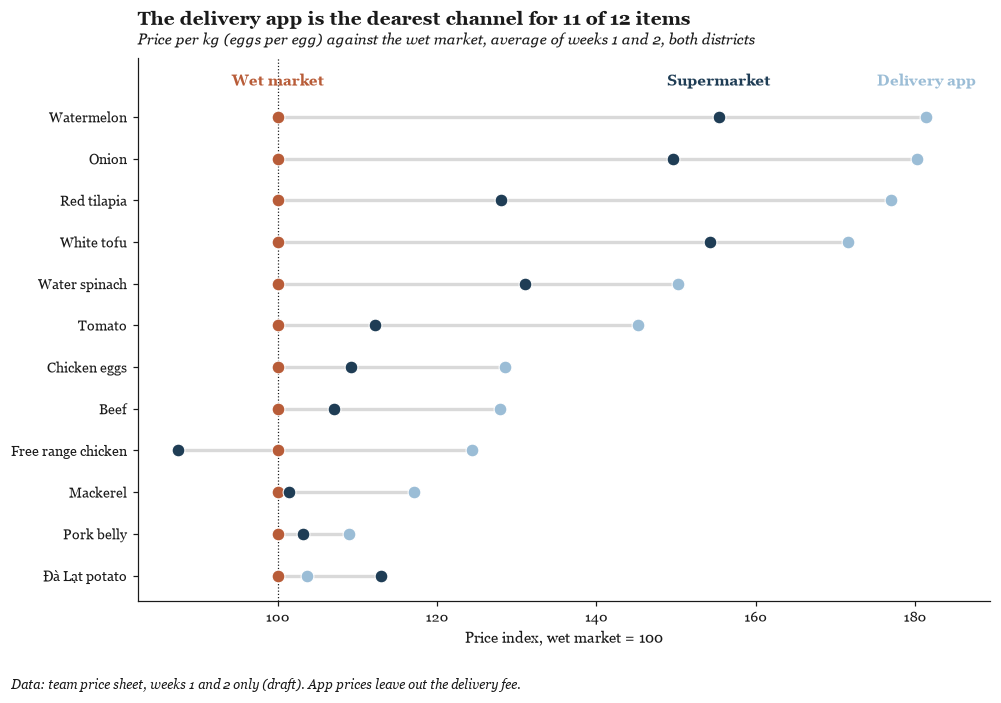

In [26]:
# M4.1b The dot plot that the brief requires: the same index as M4.1, items sorted by the app index
rel_dot = rel.sort_values("App")
fig, ax = plt.subplots(figsize=(10, 6.4))
for i, item in enumerate(rel_dot.index):
    row = rel_dot.loc[item]
    ax.plot([row.min(), row.max()], [i, i], color=LIGHT, lw=2.2, zorder=1)
    for ch in CHANNEL_ORDER:
        ax.scatter(row[ch], i, s=70, color=CHANNEL[ch], zorder=3, edgecolor="white", lw=0.7)
ax.axvline(100, color=INK, lw=0.8, ls=":")
top = len(rel_dot) - 1
for ch, dy in zip(CHANNEL_ORDER, [0.75, 0.75, 0.75]):
    ax.text(rel_dot.iloc[-1][ch], top + dy, CHANNEL_EN[ch], color=CHANNEL[ch], ha="center", fontsize=9.5, fontweight="bold")
ax.set_yticks(range(len(rel_dot)), rel_dot.index)
ax.set_ylim(-0.6, top + 1.4)
ax.set_xlim(rel_dot.min().min() - 5, rel_dot.max().max() + 8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}")
ax.set_xlabel("Price index, wet market = 100")
title(ax, f"The delivery app is the dearest channel for {n_app_dearest} of 12 items",
      "Price per kg (eggs per egg) against the wet market, average of weeks 1 and 2, both districts")
note(fig, "Data: team price sheet, weeks 1 and 2 only (draft). App prices leave out the delivery fee.", y=0.0)
save(fig, FIG / "m4_chart1b_dotplot.png")
plt.show()

### M4.2 · Chart 2 (draft): channel premium
*Task:* rank the channels by how much more they cost than the wet market.
*Why this chart:* Two 3D columns from zero show the size of each premium, and the printed values give the exact number.
*Action title:* printed by the code from the data.

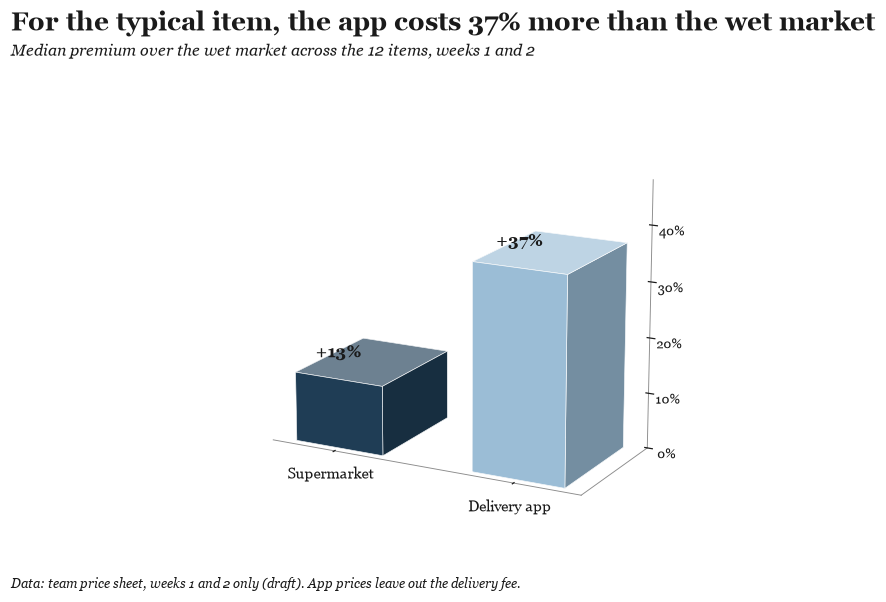

In [27]:
# M4.2 Median premium over the wet market across the 12 items, %
prem = (rel[["Siêu thị", "App"]] - 100).median()
fig = plt.figure(figsize=(8, 5.4))
ax = fig.add_subplot(projection="3d")
bars3d(ax, [0, 1], [0, 0], prem.values, [CHANNEL["Siêu thị"], CHANNEL["App"]], width=0.5, depth=0.5)
style3d(ax, elev=16, azim=-62, aspect=(2, 0.9, 1.6), zoom=1.0)
ax.set_xticks([0, 1], [CHANNEL_EN["Siêu thị"], CHANNEL_EN["App"]], fontsize=9.5)
ax.set_yticks([]); ax.set_zlim(0, prem.max() * 1.3); ax.zaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
for i, v in enumerate(prem.values):
    label3d(ax, i, -0.25, v, f"+{v:.0f}%", fontsize=11, fontweight="bold")
figure_title(fig, f"For the typical item, the app costs {prem['App']:.0f}% more than the wet market",
             "Median premium over the wet market across the 12 items, weeks 1 and 2", y=0.97)
note(fig, "Data: team price sheet, weeks 1 and 2 only (draft). App prices leave out the delivery fee.", y=0.06)
save(fig, FIG / "m4_chart2_premium.png")
plt.show()

---
# M5 · Dashboard and a second tool

**What the brief asks.** A one page dashboard in matplotlib with `subplot_mosaic` and the house style, saved as PDF and PNG (dpi 200 or more). The same dashboard, or at least two views, rebuilt in a second tool (Tableau Public, Looker Studio, Excel or Power BI). A comparison of 300 words: what was easier, what the second tool could not do, and which one my group would give to the client. For this project the dashboard is "This week's basket".

**Plan.** The mosaic holds: a KPI of this week's basket against last week, the dot plot of M4.1, the basket line of M4, the premium bar of M4.2 and a small CPI panel. The second tool is Looker Studio, with an anonymous copy of the master table (no seller names).

**Status.** Not started. My group starts after week 4, when the basket line has enough points.

---
# M6 · Hidden structure: PCA and clustering

**What the brief asks.** Items and features, scaling, PCA (scree plot and biplot with loadings explained), k means (elbow and silhouette, two random seeds), hierarchical clustering (dendrogram and the choice of linkage), cluster names and profiles, and a note on what the clusters do not mean. Items are the 12 products; features are price level and weekly change per channel.

**Plan.** A matrix of 12 items × 9 features: relative price per channel, mean weekly change per channel and volatility per channel. My group uses relative prices so that PCA does not only reflect the price level, then `StandardScaler`. K means for k = 2 to 5 with two seeds, compared with the adjusted Rand index. Ward and average linkage, compared with k means.

**Status.** Not started. Weekly change and volatility need at least six weeks of data.

---
# M7 · Many dimensions

**What the brief asks.** A heatmap of item × week of the price index, a treemap of the basket cost (group, then item), and parallel coordinates of the items across channels and districts. Notes on axis order, scaling, colour map and seriation. For CP2: three finished charts with action titles, the master table done, at least half of the field data, and the team log up to date. The sealed twist arrives at CP2.

**Plan.** The heatmap uses the diverging map of the house style centred at 100, with rows in the leaf order of the M6 dendrogram. The treemap uses the cost of the weekly basket. Parallel coordinates use the six channel and district combinations, scaled the same way, and colour by M6 cluster.

**Status.** Not started.

---
# M8 · Beyond the flat screen

**What the brief asks.** One 3D, spatial or XR view and its best 2D alternative, and a small experiment: at least five people outside the team answer the same three questions with both versions, in random order. My group records accuracy and time and reports the result honestly, even if 3D loses. For this project: a 3D block of item × week × channel against small multiples.

**Plan.** The 3D view reuses the bar style of the M2 status figure: items on one axis, weeks on the other, one block per channel, height or colour for the price index. The 2D alternative is three heatmaps side by side with one colour scale. My group writes the three questions and their answers before the test, and half of the people see 3D first.

**Status.** Not started. My group keeps 3D for this experiment and for the M2 status grid, and draws the core charts in 2D, because the brief warns against using 3D only for its look.

---
# M9 · Interaction, animation and story

**What the brief asks.** An explorer (ipywidgets or plotly) with at least three controls that answers a real question of the client, one animation that shows change better than a static chart (or evidence that small multiples work better), a hand drawn storyboard of 5 to 8 frames, and Big Idea v1. For this project: a "build your basket" explorer and an animation of the basket cost by week. A plotly HTML copy of the explorer must run without a kernel.

**Status.** Not started. The explorer needs `plotly` and `ipywidgets` from `requirements.txt`.

---
# M10 · Evaluation and improvement

**What the brief asks.** A user test with at least five people outside the team (ideally students who cook): tasks, success, time, think aloud notes, and a five second test of the main chart. A peer review with another team using the course checklist (CP4). An improvement log from v1 to v2 with at least eight changes, each with its evidence.

**Plan.** `improvement_log.csv` with the columns id, version, change, evidence, who and date. Sources of changes: the user test, the peer review, the AI audit of M4, the 2D and 3D experiment of M8 and feedback from the client.

**Status.** Not started.

---
# Appendix · AI log
My group records every use of an AI tool here and in `report/ai_log.md`. No AI tool created price data or survey answers.

| Date | Member | Tool | What the tool did | How my group checked it |
|---|---|---|---|---|
| 26/10/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Wrote the download script, `house_style.py`, the code of M2, M3 and M4 in this notebook, the M2 status figure, and first drafts of the M1 text and the data cards, based on the interview transcript and the team price sheet | *(fill in)* |
| 26/10/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Redrew the M3 and M4 charts as 3D columns, added the 3D helpers to the house style, filled the M2 gaps, wrote `CHANGELOG.md`, and built and deployed the Vietnamese website | *(fill in)* |
| 26/10/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Reran M2, M3 and M4 on the complete snapshot of weeks 1 and 2 (144 prices), updated every number in the text, and redeployed the website | *(fill in)* |